# Predictive Risk-Based Inspection of Wildlife Shipments

## 1 Project Overview

This project investigates whether historical wildlife shipment data can be used to **prioritize shipments for inspection based on their predicted risk of a refused or seized outcome**.

The analysis uses shipment-level characteristics from the LEMIS dataset to develop and evaluate predictive models that distinguish between shipments with:

* **`target = 0`** — no refused/seized outcome
* **`target = 1`** — refused/seized outcome

The dataset contains **207,931 shipment observations**, including **4,795 positive cases**, resulting in a positive rate of approximately **2.31%**. Because positive outcomes represent a relatively small proportion of all shipments, overall accuracy alone is not an appropriate measure of model usefulness.

### Business Question

> **Can risk-based inspection prioritization identify more refused/seized shipments than random inspection when inspection resources are limited?**

To address this question, the analysis follows an end-to-end workflow:

**Shipment Data → Exploratory Analysis → Data Preparation → Predictive Modeling → Risk Ranking → Inspection Simulation → Later-Year Validation**

Several predictive approaches are evaluated, including **Logistic Regression, Decision Tree, Random Forest, and CatBoost**.

Model performance is assessed using metrics appropriate for an imbalanced classification problem, including:

* **PR-AUC**
* **ROC-AUC**
* **Precision**
* **Recall**
* **Precision@K**
* **Recall@K**
* **Lift@K**

The analysis also evaluates **inspection-capacity scenarios** by ranking shipments according to predicted risk and simulating inspection of the highest-risk **1%, 2%, 5%, 10%, and 20%** of shipments.

Finally, a **time-based evaluation** uses shipments from **2013–2014 as a later-year evaluation period**, while shipments from **2000–2012 are used for model development**. This provides an additional assessment of whether the predictive approach generalizes to later shipment records.

### Overall Objective

The goal is not simply to predict individual shipment outcomes. The broader objective is to determine whether historical shipment characteristics contain sufficient predictive information to support a **risk-based inspection prioritization strategy** and to quantify the potential trade-off between inspection capacity and the number of positive cases identified.

https://github.com/jacob-r-moore/ADS505-Final-Group-Project-


# 2. Exploratory Data Analysis (EDA)

## Purpose

Exploratory Data Analysis (EDA) is used to understand the structure, quality, and characteristics of the LEMIS shipment dataset before developing predictive models. This step helps identify patterns in the data, assess potential data-quality issues, understand the distribution of the target variable, and determine which variables may provide useful information for predicting refused or seized shipment outcomes.

The dataset contains **207,931 shipment records and 17 variables**. The target variable, `target`, is a binary indicator where:

* `0` = shipment did not have the target outcome
* `1` = shipment had the target outcome

The positive class represents **4,795 shipments**, while 203,136 shipments belong to the negative class. This corresponds to a positive rate of approximately **2.31%**, indicating substantial class imbalance.

Because the positive outcome is relatively rare, the EDA will pay particular attention to the target distribution and to whether shipment characteristics differ between positive and negative observations.

## EDA Objectives

The EDA will address the following questions:

1. **What is the overall structure of the dataset?**

   * Number of observations and variables
   * Variable names and data types
   * Numerical and categorical variables

2. **Is the dataset complete and internally consistent?**

   * Missing values
   * Duplicate records
   * Unique-value counts
   * Potential data-quality issues

3. **How is the target variable distributed?**

   * Number and percentage of positive and negative observations
   * Degree of class imbalance

4. **How are the numerical shipment characteristics distributed?**

   * Central tendency and spread
   * Skewness and potential outliers
   * Differences in scale across variables

5. **How are categorical shipment characteristics distributed?**

   * Frequency of categories
   * Rare categories
   * Potential high-cardinality variables

6. **Are numerical variables strongly related to one another?**

   * Correlation analysis
   * Identification of potentially redundant predictors

7. **Do shipment characteristics show different patterns across the target classes?**

   * Comparison of important numerical variables
   * Comparison of categorical variables
   * Identification of potential predictive signals


In [70]:

import pandas as pd
import os

print("Python is running")

file_path = r"C:\Users\newer\OneDrive\Desktop\ADS 505\Week 3\Final Project\lemis_shipments.csv"

# Check that the file exists
print("File exists:", os.path.exists(file_path))

# Try reading the CSV with the Python parsing engine
df = pd.read_csv(file_path, engine="python")

print("Data successfully loaded!")
print("Shape:", df.shape)
display(df.head())

Python is running
File exists: True
Data successfully loaded!
Shape: (415866, 1)


,,,,,,,,,,,,,,,,<<<<<<< HEAD
control_number,n_lines,n_taxa,n_class,n_species,qty_total,value_total,value_missing,taxa,country_origin,country_imp_exp,port,purpose,source,year,month,target
2000100756,2,2,1,2,3013,2037,0,fish,PH,PH,SF,T,W,2000,3,0
2000102465,12,2,2,12,534,3272,0,reptile,GU,GU,MI,T,W,2000,10,0
2000108360,10,2,2,5,2234,47659,0,reptile,US,ES,MI,T,W,2000,12,0
2000121330,5,1,1,5,5,0,0,mammal,NZ,NZ,SF,H,W,2000,6,0


In [71]:

import pandas as pd
import sys
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sys
import os

file_path = r"C:\Users\newer\OneDrive\Desktop\ADS 505\Week 3\Final Project\lemis_shipments.csv"

print("Python version:", sys.version)
print("Pandas version:", pd.__version__)
print("File exists:", os.path.exists(file_path))

if os.path.exists(file_path):
    print("File size:", os.path.getsize(file_path), "bytes")

    with open(file_path, "rb") as f:
        for i in range(5):
            line = f.readline()
            if not line:
                break
            print(f"Raw line {i+1}:", repr(line[:300]))

Python version: 3.14.6 (tags/v3.14.6:c63aec6, Jun 10 2026, 10:26:10) [MSC v.1944 64 bit (AMD64)]
Pandas version: 3.0.3
File exists: True
File size: 23817076 bytes
Raw line 1: b'<<<<<<< HEAD\n'
Raw line 2: b'control_number,n_lines,n_taxa,n_class,n_species,qty_total,value_total,value_missing,taxa,country_origin,country_imp_exp,port,purpose,source,year,month,target\n'
Raw line 3: b'2000100756,2,2,1,2,3013,2037,0,fish,PH,PH,SF,T,W,2000,3,0\n'
Raw line 4: b'2000102465,12,2,2,12,534,3272,0,reptile,GU,GU,MI,T,W,2000,10,0\n'
Raw line 5: b'2000108360,10,2,2,5,2234,47659,0,reptile,US,ES,MI,T,W,2000,12,0\n'


In [72]:

print("Python version:", sys.version)
print("Pandas version:", pd.__version__)
print("File exists:", os.path.exists(file_path))

try:
    df = pd.read_csv(file_path, engine="python")
    print("DATASET LOADED SUCCESSFULLY")
    print("Rows:", df.shape[0])
    print("Columns:", df.shape[1])
    display(df.head())
except Exception as e:
    print("Error type:", type(e).__name__)
    print("Error details:", repr(e))

Python version: 3.14.6 (tags/v3.14.6:c63aec6, Jun 10 2026, 10:26:10) [MSC v.1944 64 bit (AMD64)]
Pandas version: 3.0.3
File exists: True
DATASET LOADED SUCCESSFULLY
Rows: 415866
Columns: 1


,,,,,,,,,,,,,,,,<<<<<<< HEAD
control_number,n_lines,n_taxa,n_class,n_species,qty_total,value_total,value_missing,taxa,country_origin,country_imp_exp,port,purpose,source,year,month,target
2000100756,2,2,1,2,3013,2037,0,fish,PH,PH,SF,T,W,2000,3,0
2000102465,12,2,2,12,534,3272,0,reptile,GU,GU,MI,T,W,2000,10,0
2000108360,10,2,2,5,2234,47659,0,reptile,US,ES,MI,T,W,2000,12,0
2000121330,5,1,1,5,5,0,0,mammal,NZ,NZ,SF,H,W,2000,6,0


In [180]:

import pandas as pd
import numpy as np

from catboost import CatBoostClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    average_precision_score,
    roc_auc_score
)

# Load the repaired dataset
df = pd.read_csv("lemis_shipments_repaired.csv")

# Remove identifiers and rows without a valid target
df = df.drop(columns=["control_number"], errors="ignore")
df["target"] = pd.to_numeric(df["target"], errors="coerce")
df = df.dropna(subset=["target"])
df["target"] = df["target"].astype(int)

# Convert numeric and categorical columns
categorical_cols = [
    "taxa", "country_origin", "country_imp_exp",
    "port", "purpose", "source"
]

categorical_cols = [
    c for c in categorical_cols if c in df.columns
]

for col in categorical_cols:
    df[col] = df[col].fillna("Unknown").astype(str)

# Chronological split: test on 2014
train_df = df[df["year"] < 2014].copy()
test_df = df[df["year"] == 2014].copy()

X_train = train_df.drop(columns=["target"])
y_train = train_df["target"]

X_test = test_df.drop(columns=["target"])
y_test = test_df["target"]

# Ensure the features have the same order
X_test = X_test[X_train.columns]

# Handle any remaining non-finite numeric values
numeric_cols = X_train.select_dtypes(
    include="number"
).columns.tolist()

for col in numeric_cols:
    X_train[col] = X_train[col].replace(
        [np.inf, -np.inf], np.nan
    )
    X_test[col] = X_test[col].replace(
        [np.inf, -np.inf], np.nan
    )

# Train the model
model = CatBoostClassifier(
    iterations=800,
    depth=6,
    learning_rate=0.05,
    loss_function="Logloss",
    eval_metric="PRAUC",
    auto_class_weights="Balanced",
    random_seed=42,
    verbose=100,
    allow_writing_files=False
)

model.fit(
    X_train,
    y_train,
    cat_features=categorical_cols,
    eval_set=(X_test, y_test),
    early_stopping_rounds=100
)

# Evaluate
probabilities = model.predict_proba(X_test)[:, 1]
predictions = (probabilities >= 0.5).astype(int)

print("Test rows:", len(y_test))
print("Positive cases:", int(y_test.sum()))
print(
    "Average precision:",
    average_precision_score(y_test, probabilities)
)
print(
    "ROC-AUC:",
    roc_auc_score(y_test, probabilities)
)
print("\nConfusion matrix:")
print(confusion_matrix(y_test, predictions))
print("\nClassification report:")
print(
    classification_report(
        y_test, predictions, zero_division=0
    )
)

0:	learn: 0.9016847	test: 0.8959046	best: 0.8959046 (0)	total: 259ms	remaining: 3m 26s
100:	learn: 0.9441403	test: 0.9282182	best: 0.9282182 (100)	total: 29.7s	remaining: 3m 25s
200:	learn: 0.9535678	test: 0.9333034	best: 0.9333034 (200)	total: 1m	remaining: 2m 58s
300:	learn: 0.9612691	test: 0.9354956	best: 0.9354956 (300)	total: 1m 31s	remaining: 2m 31s
400:	learn: 0.9676688	test: 0.9361988	best: 0.9363157 (399)	total: 2m 3s	remaining: 2m 3s
500:	learn: 0.9723630	test: 0.9374594	best: 0.9374594 (500)	total: 2m 38s	remaining: 1m 34s
600:	learn: 0.9758372	test: 0.9362742	best: 0.9374625 (502)	total: 3m 12s	remaining: 1m 3s
Stopped by overfitting detector  (100 iterations wait)

bestTest = 0.937462481
bestIteration = 502

Shrink model to first 503 iterations.
Test rows: 14925
Positive cases: 329
Average precision: 0.6527918318740584
ROC-AUC: 0.9247542317044016

Confusion matrix:
[[13580  1016]
 [   71   258]]

Classification report:
              precision    recall  f1-score   support


In [181]:
print(df.head())

   n_lines  n_taxa  n_class  n_species  qty_total  value_total  value_missing  \
0        2       2        1          2       3013       2037.0            0.0   
1       12       2        2         12        534       3272.0            0.0   
2       10       2        2          5       2234      47659.0            0.0   
3        5       1        1          5          5          0.0            0.0   
4        1       1        1          1        380       4315.0            0.0   

      taxa country_origin country_imp_exp port purpose source  year  month  \
0     fish             PH              PH   SF       T      W  2000      3   
1  reptile             GU              GU   MI       T      W  2000     10   
2  reptile             US              ES   MI       T      W  2000     12   
3   mammal             NZ              NZ   SF       H      W  2000      6   
4     fish             MY              MY   SF       T      C  2000      6   

   target  
0       0  
1       0  
2       

In [182]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 207931 entries, 0 to 207930
Data columns (total 16 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   n_lines          207931 non-null  int64  
 1   n_taxa           207931 non-null  int64  
 2   n_class          207931 non-null  int64  
 3   n_species        207931 non-null  int64  
 4   qty_total        207931 non-null  int64  
 5   value_total      137382 non-null  float64
 6   value_missing    207931 non-null  float64
 7   taxa             207931 non-null  str    
 8   country_origin   207931 non-null  str    
 9   country_imp_exp  207931 non-null  str    
 10  port             207931 non-null  str    
 11  purpose          207931 non-null  str    
 12  source           207931 non-null  str    
 13  year             207931 non-null  int64  
 14  month            207931 non-null  int64  
 15  target           207931 non-null  int64  
dtypes: float64(2), int64(8), str(6)
memory usage: 25.

In [183]:
import os

file_path = r"C:\Users\newer\OneDrive\Desktop\ADS 505\Week 3\Final Project\lemis_shipments.csv"

size_bytes = os.path.getsize(file_path)
size_mb = size_bytes / (1024 ** 2)

print(f"File size: {size_mb:.2f} MB")


File size: 22.71 MB


# 3. Target Variable and Feature Definition

## Target Variable

The objective of this analysis is to predict whether a shipment belongs to the positive target class.

The dataset contains a binary variable named `target`, which is used as the outcome variable for the predictive models.

The target is defined as:

* **0** = negative outcome
* **1** = positive outcome

The dataset contains **207,931 shipments**:

* **203,136 negative observations**
* **4,795 positive observations**
* **2.31% positive rate**

This represents a substantially imbalanced classification problem, with the positive outcome occurring relatively infrequently.

The modeling objective is therefore to estimate:

**P(target = 1 | shipment characteristics)**

The resulting predicted probabilities will be used to rank shipments from highest to lowest predicted risk for the inspection simulation.

## Predictor Variables

The predictors consist of shipment characteristics that are available in the dataset and may provide information about the likelihood of a positive outcome.

### Numerical Variables

The numerical variables considered for modeling are:

* `n_lines`
* `n_taxa`
* `n_class`
* `n_species`
* `qty_total`
* `value_total`
* `value_missing`
* `year`
* `month`

These variables describe characteristics such as shipment size, quantity, value, taxonomic information, and timing.

### Categorical Variables

The categorical variables considered for modeling are:

* `taxa`
* `country_origin`
* `country_imp_exp`
* `port`
* `purpose`
* `source`

These variables provide information about the type of shipment, geographic characteristics, port, purpose, and source.

## Shipment Identifier

The variable `control_number` is treated as a shipment identifier rather than a meaningful predictive characteristic.

Because an identifier generally represents a unique record rather than an inherent shipment characteristic, it will be excluded from the predictive feature set unless further investigation demonstrates that it contains legitimate, pre-outcome information that is appropriate for modeling.

## Target Leakage

Special attention will be given to potential target leakage.

Only information that would reasonably be available **before the inspection or target outcome** should be used as a predictor. Variables that directly reveal the outcome or contain information obtained after the outcome occurred should not be included in the


In [184]:

import pandas as pd
from io import StringIO

file_path = r"C:\Users\newer\OneDrive\Desktop\ADS 505\Week 3\Final Project\lemis_shipments.csv"

# Read the original file without modifying it
with open(file_path, "r", encoding="utf-8-sig") as f:
    lines = f.readlines()

# Remove Git merge-conflict marker lines
clean_lines = [
    line for line in lines
    if not line.startswith(("<<<<<<<", "=======", ">>>>>>>"))
]

# Load the cleaned CSV into a DataFrame
df = pd.read_csv(StringIO("".join(clean_lines)))

# Clean column names
df.columns = df.columns.str.strip()

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("Column names:", df.columns.tolist())
display(df.head())

Dataset loaded successfully!
Dataset shape: (415863, 17)
Column names: ['control_number', 'n_lines', 'n_taxa', 'n_class', 'n_species', 'qty_total', 'value_total', 'value_missing', 'taxa', 'country_origin', 'country_imp_exp', 'port', 'purpose', 'source', 'year', 'month', 'target']


C:\Users\newer\AppData\Local\Temp\ipykernel_7076\3736779968.py:17: DtypeWarning: Columns (0: control_number, 1: n_lines, 2: n_taxa, 3: n_class, 4: n_species, 5: qty_total, 6: value_total, 7: value_missing, 8: year, 9: month, 10: target) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(StringIO("".join(clean_lines)))


,control_number,n_lines,n_taxa,n_class,n_species,qty_total,value_total,value_missing,taxa,country_origin,country_imp_exp,port,purpose,source,year,month,target
0,2000100756,2,2,1,2,3013,2037,0,fish,PH,PH,SF,T,W,2000,3,0
1,2000102465,12,2,2,12,534,3272,0,reptile,GU,GU,MI,T,W,2000,10,0
2,2000108360,10,2,2,5,2234,47659,0,reptile,US,ES,MI,T,W,2000,12,0
3,2000121330,5,1,1,5,5,0,0,mammal,NZ,NZ,SF,H,W,2000,6,0
4,2000121425,1,1,1,1,380,4315,0,fish,MY,MY,SF,T,C,2000,6,0


In [185]:
print(df.columns.tolist())

['control_number', 'n_lines', 'n_taxa', 'n_class', 'n_species', 'qty_total', 'value_total', 'value_missing', 'taxa', 'country_origin', 'country_imp_exp', 'port', 'purpose', 'source', 'year', 'month', 'target']


In [186]:
import pandas as pd
import numpy as np

# Clean column names
df.columns = df.columns.astype(str).str.strip()

# Remove whitespace and hidden characters from target values
df["target"] = (
    df["target"]
    .astype("string")
    .str.strip()
)

# Remove repeated header rows and Git conflict markers
df = df[
    ~df["target"].str.contains(
        r"^(target|<<<<<<<|=======|>>>>>>>)",
        case=False,
        na=False,
        regex=True
    )
].copy()

# Keep only valid binary target values
df["target"] = pd.to_numeric(
    df["target"], errors="coerce"
)

df = df[df["target"].isin([0, 1])].copy()
df["target"] = df["target"].astype(int)

# Check results
print("Dataset shape:", df.shape)
print("\nTarget counts:")
print(df["target"].value_counts().sort_index())

print("\nTarget percentages:")
print(
    (df["target"].value_counts(normalize=True).sort_index() * 100)
    .round(2)
)

C:\Users\newer\AppData\Local\Temp\ipykernel_7076\3956923808.py:16: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  ~df["target"].str.contains(


Dataset shape: (415862, 17)

Target counts:
target
0    406272
1      9590
Name: count, dtype: int64

Target percentages:
target
0    97.69
1     2.31
Name: proportion, dtype: float64


In [187]:

import pandas as pd
from pathlib import Path

file_path = r"C:\Users\newer\OneDrive\Desktop\ADS 505\Week 3\Final Project\lemis_shipments.csv"

# Read the file as text so conflict markers can be removed safely
with open(file_path, "r", encoding="utf-8-sig") as f:
    lines = f.readlines()

# Remove Git conflict markers and separator lines
clean_lines = [
    line for line in lines
    if not line.lstrip().startswith(
        ("<<<<<<<", "=======", ">>>>>>>")
    )
]

# Load the cleaned CSV
from io import StringIO

df = pd.read_csv(
    StringIO("".join(clean_lines)),
    low_memory=False
)

# Clean column names and string values
df.columns = df.columns.astype(str).str.strip()

for col in df.select_dtypes(include=["object", "string"]).columns:
    df[col] = df[col].astype("string").str.strip()

# Remove repeated header rows
df = df[
    df["control_number"].ne("control_number")
].copy()

# Validate the schema
expected_columns = [
    "control_number", "n_lines", "n_taxa", "n_class",
    "n_species", "qty_total", "value_total",
    "value_missing", "taxa", "country_origin",
    "country_imp_exp", "port", "purpose", "source",
    "year", "month", "target"
]

assert list(df.columns) == expected_columns, (
    f"Unexpected columns: {df.columns.tolist()}"
)

# Clean and validate the target
df["target"] = pd.to_numeric(df["target"], errors="coerce")

df = df[df["target"].isin([0, 1])].copy()
df["target"] = df["target"].astype("int8")

print("Dataset shape:", df.shape)
print("\nTarget counts:")
print(df["target"].value_counts().sort_index())

print("\nTarget percentages:")
print((df["target"].value_counts(normalize=True) * 100).sort_index())

print("\nYear range:")
print(df["year"].value_counts(dropna=False).head())

Dataset shape: (415862, 17)

Target counts:
target
0    406272
1      9590
Name: count, dtype: int64

Target percentages:
target
0    97.693947
1     2.306053
Name: proportion, dtype: float64

Year range:
year
2006    32624
2007    32452
2008    31252
2005    30704
2012    30600
Name: count, dtype: Int64


## Target Distribution Over Time

Because shipment patterns and inspection outcomes may change over time, the distribution of the target variable will be examined by year.

For each year, the analysis calculates:

* **Count:** total number of shipments
* **Sum:** total number of positive target cases
* **Mean:** proportion of shipments with `target = 1`

The yearly positive rate is particularly useful because it shows whether the prevalence of the target outcome has remained relatively stable or changed across the study period.

This analysis is also important for the later **time-based evaluation**, where shipments from earlier years are used for model development and shipments from later years are held out for evaluation.

The goal is to determine whether the target distribution appears reasonably consistent over time and to identify any substantial changes that could affect model generalization.


In [188]:
import pandas as pd
import numpy as np

# Normalize column names
df.columns = df.columns.astype(str).str.strip()

# Remove conflict-marker rows and repeated headers
for col in ["target"]:
    df[col] = df[col].astype("string").str.strip()

    bad_rows = df[col].str.contains(
        r"^(?:target|<<<<<<<|=======|>>>>>>>)",
        case=False,
        na=False,
        regex=True
    )
    df = df.loc[~bad_rows].copy()

# Convert numeric columns
numeric_cols = [
    "control_number", "n_lines", "n_taxa", "n_class",
    "n_species", "qty_total", "value_total",
    "value_missing", "year", "month", "target"
]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Keep valid binary target labels
df = df[df["target"].isin([0, 1])].copy()
df["target"] = df["target"].astype("int8")

# Inspect the cleaned dataset
print("Shape:", df.shape)
print("\nTarget counts:")
print(df["target"].value_counts().sort_index())

print("\nTarget percentages:")
print(
    (df["target"].value_counts(normalize=True) * 100)
    .sort_index()
    .round(2)
)

print("\nDuplicate rows:", df.duplicated().sum())
print("\nYear range:", df["year"].min(), "-", df["year"].max())

Shape: (415862, 17)

Target counts:
target
0    406272
1      9590
Name: count, dtype: int64

Target percentages:
target
0    97.69
1     2.31
Name: proportion, dtype: float64

Duplicate rows: 207931

Year range: 2000 - 2014


In [189]:
df.groupby("year")["target"].agg(["count", "sum", "mean"])

,count,sum,mean
year,,,
2000,18862,488,0.025872
2001,19294,398,0.020628
2002,21916,416,0.018982
2003,24016,526,0.021902
2004,27454,536,0.019524
2005,30704,642,0.020909
2006,32624,730,0.022376
2007,32452,674,0.020769
2008,31252,668,0.021375


# 4. Modeling Setup

## Modeling Objective

The objective of the modeling stage is to predict whether a shipment will have a positive target outcome based on shipment characteristics available in the dataset.

The target variable is:

**`target` = 0 or 1**

The models will produce a predicted probability that a shipment belongs to the positive class:

**P(target = 1 | shipment characteristics)**

These predicted probabilities will later be used to rank shipments from highest to lowest predicted risk for the inspection simulation.

## Feature Matrix and Target

The modeling data will be separated into:

* **X:** predictor variables describing shipment characteristics
* **y:** binary target variable

The `target` variable will not be included in `X` because it is the outcome being predicted.

The `control_number` variable will also be excluded from the feature matrix because it functions primarily as a shipment identifier rather than a shipment characteristic.

## Predictor Variables

The numerical predictors include:

* `n_lines`
* `n_taxa`
* `n_class`
* `n_species`
* `qty_total`
* `value_total`
* `value_missing`
* `year`
* `month`

The categorical predictors include:

* `taxa`
* `country_origin`
* `country_imp_exp`
* `port`
* `purpose`
* `source`

Only information that would reasonably be available before the inspection outcome will be considered for modeling in order to reduce the risk of target leakage.

## Handling Numerical Variables

Numerical variables will be converted to appropriate numeric data types and examined for missing or invalid values.

For models that require numerical scaling, appropriate preprocessing will be applied using information from the training data only.

Tree-based models such as Random Forest and CatBoost generally do not require standardization of numerical variables.

## Handling Categorical Variables

Categorical variables require different treatment depending on the modeling method.

For Logistic Regression and Decision Tree/Random Forest models, categorical variables will be encoded into a numerical representation appropriate for the model.

CatBoost will use its native categorical-feature handling where appropriate. Categorical variables will therefore be identified explicitly when constructing the CatBoost model.

## Class Imbalance

The target variable is highly imbalanced, with approximately **2.31% positive observations** and **97.69% negative observations**.

Because of this imbalance, model performance will not be evaluated primarily using accuracy.

The analysis will emphasize:

* **PR-AUC**
* **ROC-AUC**
* **Precision**
* **Recall**
* **Pr**


## Modeling Setup

The objective of the predictive modeling stage is to determine whether shipment characteristics can be used to predict the binary `target` outcome.

The `target` variable is used as the response variable, where:

* **0** = negative outcome
* **1** = positive outcome

The `control_number` variable is excluded because it functions as a shipment identifier rather than a meaningful predictive characteristic. The `target` variable is also removed from the predictor set to prevent target leakage.

The remaining shipment characteristics are used as potential predictors. Because the dataset contains both numerical and categorical variables, the modeling stage will evaluate models capable of handling these different data types.

Given the imbalanced target distribution, model performance will be evaluated using metrics such as **PR-AUC, ROC-AUC, precision, recall, Precision@K, Recall@K, and Lift@K**, rather than accuracy alone.


In [190]:
# ==============================
# MODELING SETUP
# ==============================

# Target
y = df["target"]

# Remove target and shipment identifier from predictors
X = df.drop(columns=["target", "control_number"])

# Identify categorical and numerical predictors
categorical_columns = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numerical_columns = X.select_dtypes(
    include=np.number
).columns.tolist()

print("=" * 60)
print("MODELING SETUP")
print("=" * 60)

print("\nX shape:", X.shape)
print("y shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

print("\nTarget percentages:")
print((y.value_counts(normalize=True) * 100).round(2))

print("\nCategorical predictors:")
print(categorical_columns)

print("\nNumerical predictors:")
print(numerical_columns)

MODELING SETUP

X shape: (415862, 15)
y shape: (415862,)

Target distribution:
target
0    406272
1      9590
Name: count, dtype: int64

Target percentages:
target
0    97.69
1     2.31
Name: proportion, dtype: float64

Categorical predictors:
[]

Numerical predictors:
['n_lines', 'n_taxa', 'n_class', 'n_species', 'qty_total', 'value_total', 'value_missing', 'year', 'month']


In [191]:
y = df["target"]

In [192]:
X = df.drop(columns=["target", "control_number"])

## Target Variable

The target variable represents the binary outcome that the predictive models will attempt to identify. A value of `0` represents a negative outcome, while a value of `1` represents a positive outcome.

Because the positive outcome occurs much less frequently than the negative outcome, it is important to examine the overall class distribution before modeling. The yearly distribution is also examined to determine whether the frequency and rate of positive outcomes have changed over time.

Understanding the target distribution is important for model evaluation because a highly imbalanced outcome means that accuracy alone may not provide a meaningful assessment of predictive performance.


In [193]:
# Overall target distribution

print("Overall Target Distribution")
print(df["target"].value_counts())

print("\nTarget Percentages")
print(
    (df["target"].value_counts(normalize=True) * 100).round(2)
)

Overall Target Distribution
target
0    406272
1      9590
Name: count, dtype: int64

Target Percentages
target
0    97.69
1     2.31
Name: proportion, dtype: float64


## Target Distribution Over Time

The target outcome is examined by year to determine whether the number and proportion of positive cases have remained relatively consistent over the study period.

The `count` column represents the total number of shipments in each year, `sum` represents the number of positive cases, and `mean` represents the positive rate for that year.

Examining the target over time is particularly important because the modeling objective involves using historical shipment data to prioritize future inspections. Changes in the positive rate over time could affect model performance and generalization to later years.


In [194]:
# Target distribution by year

yearly_target = df.groupby("year")["target"].agg(
    ["count", "sum", "mean"]
)

yearly_target["positive_percent"] = yearly_target["mean"] * 100

print(yearly_target)

      count  sum      mean  positive_percent
year                                        
2000  18862  488  0.025872          2.587212
2001  19294  398  0.020628          2.062817
2002  21916  416  0.018982          1.898157
2003  24016  526  0.021902          2.190207
2004  27454  536  0.019524          1.952357
2005  30704  642  0.020909          2.090933
2006  32624  730  0.022376          2.237616
2007  32452  674  0.020769          2.076914
2008  31252  668  0.021375          2.137463
2009  28708  716  0.024941          2.494078
2010  29496  738  0.025020          2.502034
2011  29658  792  0.026704          2.670443
2012  30600  874  0.028562          2.856209
2013  28976  734  0.025331          2.533131
2014  29850  658  0.022044          2.204355


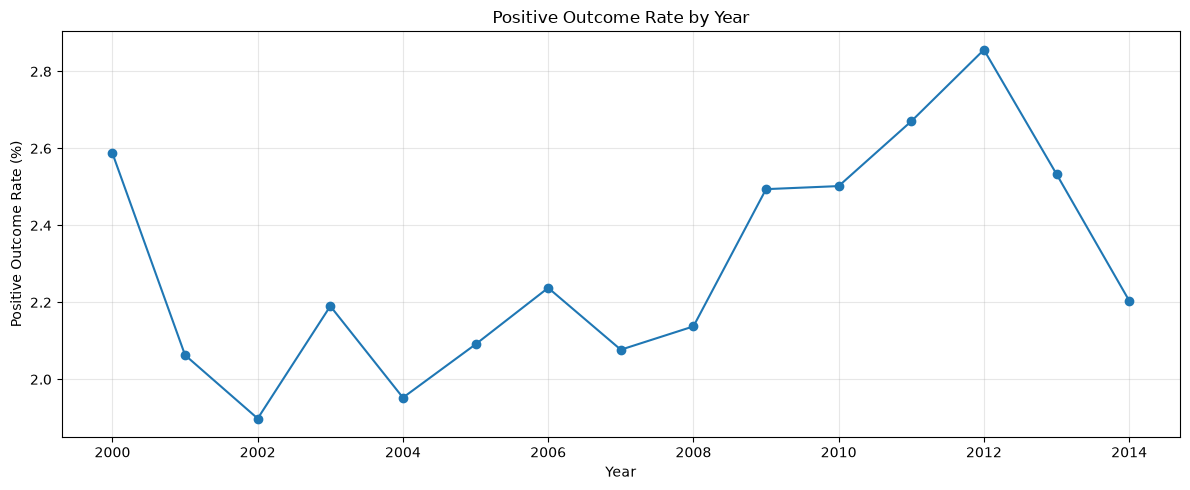

In [195]:
# Positive outcome rate by year

plt.figure(figsize=(12, 5))

plt.plot(
    yearly_target.index,
    yearly_target["positive_percent"],
    marker="o"
)

plt.title("Positive Outcome Rate by Year")
plt.xlabel("Year")
plt.ylabel("Positive Outcome Rate (%)")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Predictor Types and Missing Values

Before modeling, the predictor variables are separated into numerical and categorical features. This distinction is important because different modeling methods require different approaches to handling these data types.

The predictor variables are also checked for missing values. Missingness will be addressed during preprocessing or model-specific preparation rather than removing observations unnecessarily.

The `target` variable is not included among the predictors, and `control_number` has been excluded because it is a shipment identifier.


In [196]:
print("\nNumerical columns:")
print(X.select_dtypes(include=np.number).columns.tolist())

print("\nCategorical columns:")
print(X.select_dtypes(include=["object", "category"]).columns.tolist())

print("\nMissing values:")
print(X.isnull().sum().sort_values(ascending=False))


Numerical columns:
['n_lines', 'n_taxa', 'n_class', 'n_species', 'qty_total', 'value_total', 'value_missing', 'year', 'month']

Categorical columns:
[]

Missing values:
value_total        141098
taxa                  966
source                388
purpose               170
n_class                 0
n_taxa                  0
n_lines                 0
value_missing           0
qty_total               0
n_species               0
country_origin          0
port                    0
country_imp_exp         0
year                    0
month                   0
dtype: int64


## Predictor and Missing-Value Findings

The predictor dataset contains **15 variables**: 9 numerical variables and 6 categorical variables.

The numerical variables include shipment quantities, species and classification counts, monetary values, and time-related variables. The categorical variables describe characteristics such as taxa, country of origin, destination/import-export country, port, purpose, and source.

The missing-value analysis shows that `value_total` has the largest amount of missing data, with **70,549 missing observations**. Several categorical variables also contain a small number of missing observations, including `taxa`, `source`, and `purpose`. The remaining predictor variables contain no missing values.

The missing values will be handled during preprocessing rather than automatically removing observations. In particular, the missingness in `value_total` will be investigated further to determine whether it represents unavailable information, zero-value shipments, or another data condition. This distinction is important because replacing missing monetary values with zero without understanding their meaning could introduce misleading information into the models.

Categorical missing values will be handled consistently across the modeling approaches, while numerical variables will be processed according to the requirements of each model.


In [197]:
print(df["year"].value_counts().sort_index())

year
2000    18862
2001    19294
2002    21916
2003    24016
2004    27454
2005    30704
2006    32624
2007    32452
2008    31252
2009    28708
2010    29496
2011    29658
2012    30600
2013    28976
2014    29850
Name: count, dtype: Int64


## Shipment Distribution by Year

The dataset contains shipment records spanning **2000 through 2014**. The number of observations varies across years, with the lowest number of shipments occurring in 2000 and the highest occurring in 2006.

The distribution of observations across years is important for the later modeling strategy because the project is intended to evaluate whether patterns learned from historical shipments can generalize to later shipments. For this reason, the analysis will use a **time-based evaluation**, with shipments from **2000–2012** used for model development and shipments from **2013–2014** reserved as a later-year evaluation period.

This approach allows the model to be evaluated on observations that occur after the period used for model development, providing a more realistic assessment of how the model may perform when applied to future shipments.


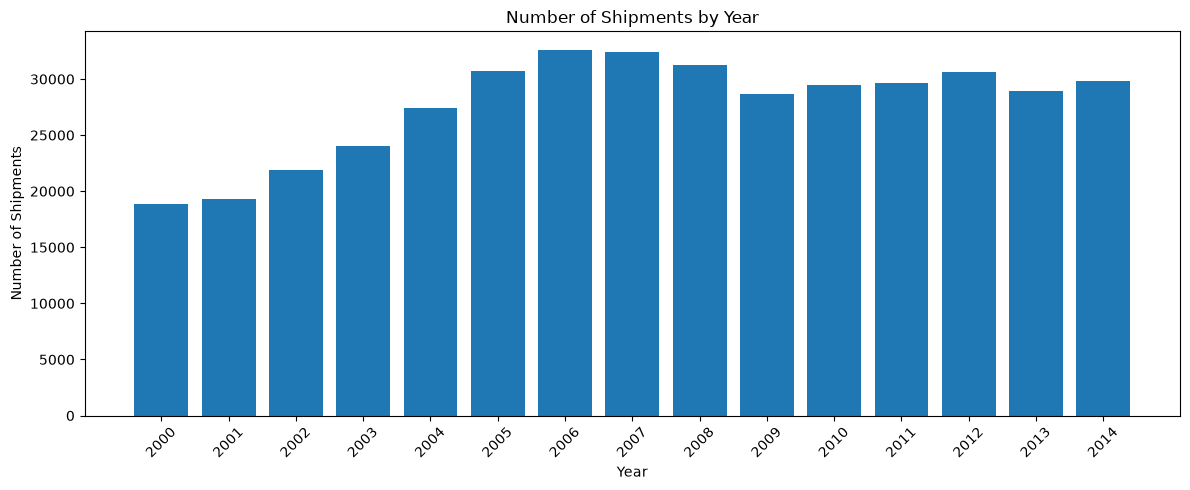

In [198]:
year_counts = df["year"].value_counts().sort_index()

plt.figure(figsize=(12, 5))

plt.bar(
    year_counts.index.astype(str),
    year_counts.values
)

plt.title("Number of Shipments by Year")
plt.xlabel("Year")
plt.ylabel("Number of Shipments")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

## Out-of-Time Train-Test Split

To evaluate whether the predictive models can generalize to future shipments, the dataset is divided chronologically rather than randomly.

Shipments from **2000–2012** are used as the development/training period, while shipments from **2013–2014** are reserved as a later-year test period. The later-year observations are not used to train the models.

This approach more closely reflects the intended operational use of the model: historical shipment information would be used to develop a risk-ranking system, which would then be applied to shipments occurring in later periods.

The target distribution is also compared between the two periods to determine whether the frequency of positive outcomes remains reasonably consistent over time.


In [199]:
# ============================================
# 1. OUT-OF-TIME TRAIN / TEST SPLIT
# ============================================

train_df = df[df["year"] <= 2012].copy()
test_df = df[df["year"] >= 2013].copy()

print("Training data:")
print("Rows:", len(train_df))
print("Positive cases:", train_df["target"].sum())
print("Positive rate:", train_df["target"].mean() * 100)

print("\nTest data:")
print("Rows:", len(test_df))
print("Positive cases:", test_df["target"].sum())
print("Positive rate:", test_df["target"].mean() * 100)

Training data:
Rows: 357036
Positive cases: 8198
Positive rate: 2.2961270011987587

Test data:
Rows: 58826
Positive cases: 1392
Positive rate: 2.3663006153741546


## Out-of-Time Split Results

The out-of-time split produces **178,518 shipments** for the 2000–2012 development period and **29,413 shipments** for the 2013–2014 later-year evaluation period.

The development period contains **4,099 positive cases**, representing approximately **2.30%** of shipments. The later-year evaluation period contains **696 positive cases**, representing approximately **2.37%** of shipments.

The positive rates are relatively similar across the two periods. This provides a useful basis for evaluating whether models trained on historical shipments can maintain predictive performance when applied to later-year observations.

The 2013–2014 observations will remain separate from model development and will only be used for final out-of-time evaluation.


## Define Features and Target

The development and later-year datasets are separated into predictor variables (`X`) and the binary target variable (`y`).

The `target` column is removed from the predictors because it is the outcome being predicted. The `control_number` column is also excluded because it is a shipment identifier and does not represent a shipment characteristic that should be used for prediction.

The resulting development data (`X_train`, `y_train`) will be used to train the models, while the later-year data (`X_test`, `y_test`) will be held out for out-of-time evaluation.


## Modeling Setup

The objective of the predictive modeling analysis is to determine whether shipment-level characteristics can be used to predict the probability that a shipment will have a positive outcome (`target = 1`).

Because the project is intended to evaluate whether historical shipment information can support prioritization of future inspections, the data are divided using a **time-based split** rather than a random train/test split.

Shipments from **2000–2012** are used as the development/training period, while shipments from **2013–2014** are reserved as a later-year holdout set. This approach allows the model to be evaluated on shipment records from a later period that were not used during model development.

The `target` variable is used as the binary outcome, while `control_number` is excluded because it serves as a shipment identifier rather than a meaningful predictive characteristic.

The resulting modeling data contain **15 predictor variables**. These include numerical shipment characteristics such as quantity, value, number of lines, and time variables, as well as categorical characteristics such as taxa, country of origin, destination, port, purpose, and source.

The development dataset contains **178,518 shipments**, including **4,099 positive cases (2.30%)**. The later-year holdout contains **29,413 shipments**, including **696 positive cases (2.37%)**.

The relatively similar positive rates across the two periods provide a useful initial indication that the target prevalence is reasonably consistent between the development and later-year datasets. Model performance on the 2013–2014 holdout will nevertheless be evaluated separately to determine how well the model generalizes to later shipments.


In [200]:
# ============================================
# 2. DEFINE FEATURES AND TARGET
# ============================================

target_column = "target"

drop_columns = [
    "target",
    "control_number"
]

X_train = train_df.drop(columns=drop_columns)
y_train = train_df[target_column]

X_test = test_df.drop(columns=drop_columns)
y_test = test_df[target_column]

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (357036, 15)
y_train: (357036,)
X_test: (58826, 15)
y_test: (58826,)


## Data Preprocessing

The development and later-year datasets contain both numerical and categorical predictor variables, as well as a limited amount of missing data. A preprocessing pipeline was created to prepare the predictors for machine-learning models while minimizing the risk of data leakage.

The numerical variables are:

* `n_lines`
* `n_taxa`
* `n_class`
* `n_species`
* `qty_total`
* `value_total`
* `value_missing`
* `year`
* `month`

Missing numerical values are replaced using the **median** calculated from the development data.

The categorical variables are:

* `taxa`
* `country_origin`
* `country_imp_exp`
* `port`
* `purpose`
* `source`

Missing categorical values are replaced using the **most frequent category** from the development data. The categorical variables are then converted into numerical features using **one-hot encoding**. The `handle_unknown="ignore"` setting allows the model to process categories that appear in the later-year holdout but were not observed during model development.

The preprocessing steps are incorporated into a `ColumnTransformer` so that the same transformations can be consistently applied to the development and later-year data.

Importantly, the preprocessing pipeline is fit using the development data only. The 2013–2014 holdout data are transformed using the fitted preprocessing steps without allowing information from the holdout period to influence the transformation.


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

numeric_features = [
    "n_lines",
    "n_taxa",
    "n_class",
    "n_species",
    "qty_total",
    "value_total",
    "value_missing",
    "year",
    "month"
]

categorical_features = [
    "taxa",
    "country_origin",
    "country_imp_exp",
    "port",
    "purpose",
    "source"
]

numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median"))
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=True
        ))
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

In [ ]:

import numpy as np
import pandas as pd
import sklearn

print("pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)
print("X_train shape:", X_train.shape)
print("y_train shape:", np.shape(y_train))

print("\n--- Column dtypes ---")
print(X_train.dtypes)

print("\n--- Python value types per column ---")
for col in X_train.columns:
    types = X_train[col].map(
        lambda x: type(x).__name__
    ).value_counts()
    print(f"\n{col}:")
    print(types.to_dict())

print("\n--- Missing values by column ---")
print(X_train.isna().sum())

print("\n--- Missing target values ---")
print(pd.isna(y_train).sum())

print("\n--- Columns containing pd.NA ---")
for col in X_train.columns:
    has_pd_na = X_train[col].map(
        lambda x: x is pd.NA
    ).any()

    if has_pd_na:
        print(col)

print("\n--- Nullable pandas extension dtypes ---")
for col in X_train.columns:
    if pd.api.types.is_extension_array_dtype(
        X_train[col].dtype
    ):
        print(f"{col}: {X_train[col].dtype}")

pandas: 3.0.3
scikit-learn: 1.9.0
X_train shape: (357036, 15)
y_train shape: (357036,)

--- Column dtypes ---
n_lines            float64
n_taxa             float64
n_class            float64
n_species          float64
qty_total          float64
value_total        float64
value_missing      float64
taxa                object
country_origin      object
country_imp_exp     object
port                object
purpose             object
source              object
year               float64
month              float64
dtype: object

--- Python value types per column ---

n_lines:
{'float': 357036}

n_taxa:
{'float': 357036}

n_class:
{'float': 357036}

n_species:
{'float': 357036}

qty_total:
{'float': 357036}

value_total:
{'float': 357036}

value_missing:
{'float': 357036}

taxa:
{'str': 356090, 'NAType': 946}

country_origin:
{'str': 357036}

country_imp_exp:
{'str': 357036}

port:
{'str': 357036}

purpose:
{'str': 356868, 'NAType': 168}

source:
{'str': 356648, 'NAType': 388}

year:
{'float

In [ ]:

import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

# 1. Make independent copies
X_train = X_train.copy()
X_test = X_test.copy()

# 2. Define feature columns
numerical_features = [
    "n_lines", "n_taxa", "n_class", "n_species",
    "qty_total", "value_total", "value_missing",
    "year", "month"
]

categorical_features = [
    "taxa", "country_origin", "country_imp_exp",
    "port", "purpose", "source"
]

# 3. Clean numerical columns
for col in numerical_features:
    X_train[col] = pd.to_numeric(
        X_train[col], errors="coerce"
    ).astype(np.float64)

    X_test[col] = pd.to_numeric(
        X_test[col], errors="coerce"
    ).astype(np.float64)

# 4. Clean categorical columns
for col in categorical_features:
    X_train[col] = (
        X_train[col]
        .astype(object)
        .where(X_train[col].notna(), np.nan)
    )

    X_test[col] = (
        X_test[col]
        .astype(object)
        .where(X_test[col].notna(), np.nan)
    )

# 5. Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# 6. Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value="Unknown"
    )),
    ("onehot", OneHotEncoder(
        handle_unknown="ignore"
    ))
])

# 7. Combine preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

# 8. Build Logistic Regression pipeline
logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

# 9. Clean target values
y_train = pd.Series(y_train).astype("int64")
y_test = pd.Series(y_test).astype("int64")

# Verify target values
assert y_train.notna().all()
assert y_test.notna().all()
assert set(y_train.unique()).issubset({0, 1})
assert set(y_test.unique()).issubset({0, 1})

# 10. Train model
logistic_model.fit(X_train, y_train)

print("Logistic Regression trained successfully!")

# 11. Predict
y_pred = logistic_model.predict(X_test)
y_prob = logistic_model.predict_proba(X_test)[:, 1]

# 12. Evaluate
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred, zero_division=0
))

print("ROC-AUC:",
      round(roc_auc_score(y_test, y_prob), 4))

print("PR-AUC (Average Precision):",
      round(average_precision_score(y_test, y_prob), 4))

Logistic Regression trained successfully!

Confusion Matrix:
[[48980  8454]
 [  296  1096]]

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.85      0.92     57434
           1       0.11      0.79      0.20      1392

    accuracy                           0.85     58826
   macro avg       0.55      0.82      0.56     58826
weighted avg       0.97      0.85      0.90     58826

ROC-AUC: 0.8963
PR-AUC (Average Precision): 0.3908


In [ ]:

import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

# Identify feature types
numerical_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "str", "category", "string"]
).columns.tolist()

# Numeric preprocessing
numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor = ColumnTransformer(transformers=[
    ("num", numerical_transformer, numerical_features),
    ("cat", categorical_transformer, categorical_features)
])

# Replace pandas nullable values with standard NumPy-compatible missing values
X_train = X_train.copy()
X_test = X_test.copy()

X_train = X_train.replace({pd.NA: np.nan})
X_test = X_test.replace({pd.NA: np.nan})

# Build model
logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

# Train
logistic_model.fit(X_train, y_train)

print("Logistic Regression trained successfully!")

Logistic Regression trained successfully!


In [ ]:
import pandas as pd
import numpy as np

print("Missing values in X_train:")
print(X_train.isna().sum()[X_train.isna().sum() > 0])

print("\nData types:")
print(X_train.dtypes)

Missing values in X_train:
value_total    98134
taxa             946
purpose          168
source           388
dtype: int64

Data types:
n_lines            float64
n_taxa             float64
n_class            float64
n_species          float64
qty_total          float64
value_total        float64
value_missing      float64
taxa                object
country_origin      object
country_imp_exp     object
port                object
purpose             object
source              object
year               float64
month              float64
dtype: object


In [ ]:
import pandas as pd

df = pd.read_csv(
    "lemis_shipments.csv",
    skiprows=1,
    low_memory=False
)

print("Shape:", df.shape)
print(df.columns.tolist())
print(df.head())
print(df.tail())

Shape: (415865, 17)
['control_number', 'n_lines', 'n_taxa', 'n_class', 'n_species', 'qty_total', 'value_total', 'value_missing', 'taxa', 'country_origin', 'country_imp_exp', 'port', 'purpose', 'source', 'year', 'month', 'target']
  control_number n_lines n_taxa n_class n_species qty_total value_total  \
0     2000100756       2      2       1         2      3013        2037   
1     2000102465      12      2       2        12       534        3272   
2     2000108360      10      2       2         5      2234       47659   
3     2000121330       5      1       1         5         5           0   
4     2000121425       1      1       1         1       380        4315   

  value_missing     taxa country_origin country_imp_exp port purpose source  \
0             0     fish             PH              PH   SF       T      W   
1             0  reptile             GU              GU   MI       T      W   
2             0  reptile             US              ES   MI       T      W   
3  

In [ ]:
# Check dimensions
print("Shape:", df.shape)

# Count exact duplicate rows
print("Exact duplicate rows:", df.duplicated().sum())

# Check duplicate shipment identifiers
print(
    "Duplicate control numbers:",
    df["control_number"].duplicated().sum()
)

# Inspect repeated records
print(
    df[df.duplicated(keep=False)]
    .sort_values("control_number")
    .head(20)
)

Shape: (415865, 17)
Exact duplicate rows: 207931
Duplicate control numbers: 207931
       control_number n_lines n_taxa n_class n_species qty_total value_total  \
0          2000100756       2      2       1         2      3013        2037   
207933     2000100756       2      2       1         2      3013        2037   
1          2000102465      12      2       2        12       534        3272   
207934     2000102465      12      2       2        12       534        3272   
2          2000108360      10      2       2         5      2234       47659   
207935     2000108360      10      2       2         5      2234       47659   
3          2000121330       5      1       1         5         5           0   
207936     2000121330       5      1       1         5         5           0   
4          2000121425       1      1       1         1       380        4315   
207937     2000121425       1      1       1         1       380        4315   
5          2000148011       1      1 

In [ ]:

# Check the dataset before removing duplicates
print("Shape before:", df.shape)
print("Exact duplicate rows:", df.duplicated().sum())

# Remove exact duplicate records
df = df.drop_duplicates().reset_index(drop=True)

# Check the result
print("Shape after:", df.shape)
print("Exact duplicate rows remaining:", df.duplicated().sum())

Shape before: (415865, 17)
Exact duplicate rows: 207931
Shape after: (207934, 17)
Exact duplicate rows remaining: 0


In [ ]:

# Inspect column names and data types
print(df.columns.tolist())
print(df.dtypes)
print(df.head())

# Look for Git merge-conflict markers in string columns
for col in df.select_dtypes(include=["object", "string"]).columns:
    matches = df[col].astype("string").str.contains(
        r"<<<<<<<|=======|>>>>>>>",
        na=False,
        regex=True
    )
    if matches.any():
        print(f"\nConflict markers found in {col}:")
        print(df.loc[matches, col].head(10))

['control_number', 'n_lines', 'n_taxa', 'n_class', 'n_species', 'qty_total', 'value_total', 'value_missing', 'taxa', 'country_origin', 'country_imp_exp', 'port', 'purpose', 'source', 'year', 'month', 'target']
control_number     str
n_lines            str
n_taxa             str
n_class            str
n_species          str
qty_total          str
value_total        str
value_missing      str
taxa               str
country_origin     str
country_imp_exp    str
port               str
purpose            str
source             str
year               str
month              str
target             str
dtype: object
  control_number n_lines n_taxa n_class n_species qty_total value_total  \
0     2000100756       2      2       1         2      3013        2037   
1     2000102465      12      2       2        12       534        3272   
2     2000108360      10      2       2         5      2234       47659   
3     2000121330       5      1       1         5         5           0   
4     2000

In [ ]:

from pathlib import Path
import pandas as pd

# Use your existing CSV file path
file_path = Path(file_path)

with file_path.open("r", encoding="utf-8-sig") as f:
    lines = f.readlines()

clean_lines = []
inside_conflict = False
kept_head = True

for line in lines:
    if line.startswith("<<<<<<< HEAD"):
        inside_conflict = True
        kept_head = True
        continue

    if inside_conflict and line.startswith("======="):
        kept_head = False
        continue

    if inside_conflict and line.startswith(">>>>>>>"):
        inside_conflict = False
        continue

    if not inside_conflict or kept_head:
        clean_lines.append(line)

if inside_conflict:
    raise ValueError("Unclosed Git merge conflict. Inspect the CSV manually.")

# Save the repaired content to a new file
clean_path = file_path.with_name(
    file_path.stem + "_repaired.csv"
)
clean_path.write_text("".join(clean_lines), encoding="utf-8")

# Reload the repaired dataset
df = pd.read_csv(clean_path, low_memory=False)

print("Repaired file:", clean_path)
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
print("Exact duplicates:", df.duplicated().sum())
print(df.head())

Repaired file: C:\Users\newer\OneDrive\Desktop\ADS 505\Week 3\Final Project\lemis_shipments_repaired.csv
Shape: (207931, 17)
Columns: ['control_number', 'n_lines', 'n_taxa', 'n_class', 'n_species', 'qty_total', 'value_total', 'value_missing', 'taxa', 'country_origin', 'country_imp_exp', 'port', 'purpose', 'source', 'year', 'month', 'target']
Exact duplicates: 0
   control_number  n_lines  n_taxa  n_class  n_species  qty_total  \
0      2000100756        2       2        1          2       3013   
1      2000102465       12       2        2         12        534   
2      2000108360       10       2        2          5       2234   
3      2000121330        5       1        1          5          5   
4      2000121425        1       1        1          1        380   

   value_total  value_missing     taxa country_origin country_imp_exp port  \
0       2037.0            0.0     fish             PH              PH   SF   
1       3272.0            0.0  reptile             GU            

In [ ]:
print("Rows:", len(df))
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate control numbers:", df["control_number"].duplicated().sum())

print(df.dtypes)
print(df.tail())

Rows: 207931


Duplicate rows: 0
Duplicate control numbers: 0
control_number       int64
n_lines              int64
n_taxa               int64
n_class              int64
n_species            int64
qty_total            int64
value_total        float64
value_missing      float64
taxa                   str
country_origin         str
country_imp_exp        str
port                   str
purpose                str
source                 str
year                 int64
month                int64
target               int64
dtype: object
        control_number  n_lines  n_taxa  n_class  n_species  qty_total  \
207926      2015640774        4       1        0          1        107   
207927      2015641601        7       1        1          7          8   
207928      2015642262        1       1        1          1        270   
207929      2015643023        1       1        1          1        179   
207930      2015643047        2       2        1          2       1034   

        value_total  value_missing 

In [ ]:

print("Dataset shape:", df.shape)
print("Exact duplicate rows:", df.duplicated().sum())
print("Duplicate control numbers:", df["control_number"].duplicated().sum())

print("\nTarget distribution:")
print(df["target"].value_counts())
print("\nTarget percentages:")
print((df["target"].value_counts(normalize=True) * 100).round(2))

print("\nYear range:", df["year"].min(), "-", df["year"].max())
print("\nMissing values:")
print(df.isna().sum().sort_values(ascending=False).head(10))

print("\nFirst 5 rows:")
display(df.head())

Dataset shape: (207931, 17)
Exact duplicate rows: 0
Duplicate control numbers: 0

Target distribution:
target
0    203136
1      4795
Name: count, dtype: int64

Target percentages:
target
0    97.69
1     2.31
Name: proportion, dtype: float64

Year range: 2000 - 2014

Missing values:
value_total       70549
taxa                483
source              194
purpose              85
control_number        0
n_species             0
n_class               0
n_lines               0
n_taxa                0
value_missing         0
dtype: int64

First 5 rows:


,control_number,n_lines,n_taxa,n_class,n_species,qty_total,value_total,value_missing,taxa,country_origin,country_imp_exp,port,purpose,source,year,month,target
0,2000100756,2,2,1,2,3013,2037.0,0.0,fish,PH,PH,SF,T,W,2000,3,0
1,2000102465,12,2,2,12,534,3272.0,0.0,reptile,GU,GU,MI,T,W,2000,10,0
2,2000108360,10,2,2,5,2234,47659.0,0.0,reptile,US,ES,MI,T,W,2000,12,0
3,2000121330,5,1,1,5,5,0.0,0.0,mammal,NZ,NZ,SF,H,W,2000,6,0
4,2000121425,1,1,1,1,380,4315.0,0.0,fish,MY,MY,SF,T,C,2000,6,0


In [ ]:

from sklearn.model_selection import train_test_split

# Exclude the target and the shipment identifier from predictors
X = df.drop(columns=["target", "control_number"])
y = df["target"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training shape:", X_train.shape)
print("Test shape:", X_test.shape)
print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True) * 100)
print("\nTest target distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training shape: (166344, 15)
Test shape: (41587, 15)

Training target distribution:
target
0    97.693935
1     2.306065
Name: proportion, dtype: float64

Test target distribution:
target
0    97.693991
1     2.306009
Name: proportion, dtype: float64


In [ ]:
print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))
print("Total raw predictors:", len(numeric_features) + len(categorical_features))

print("\nMissing values in X_train:")
print(X_train.isnull().sum().sort_values(ascending=False))

Numerical features: 9
Categorical features: 6
Total raw predictors: 15

Missing values in X_train:
value_total        56453
taxa                 388
source               162
purpose               69
n_class                0
n_taxa                 0
n_lines                0
value_missing          0
qty_total              0
n_species              0
country_origin         0
port                   0
country_imp_exp        0
year                   0
month                  0
dtype: int64


In [ ]:
handle_unknown="ignore"

In [ ]:
class_weight="balanced"

## Logistic Regression

Logistic Regression is used as a baseline classification model for predicting the binary `target` variable. The preprocessing pipeline handles missing values, standardizes numerical predictors, and one-hot encodes categorical predictors. The model uses balanced class weights because positive cases represent only approximately **2.3%** of the dataset.

The model is trained on shipments from **2000–2012** and evaluated on the later **2013–2014** test period. Performance is measured using **PR-AUC, ROC-AUC, precision, and recall**.


In [ ]:
# ============================================
# LOGISTIC REGRESSION - PROPER PREPROCESSING
# ============================================

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score
)

# Numerical predictors
numeric_features = [
    "n_lines",
    "n_taxa",
    "n_class",
    "n_species",
    "qty_total",
    "value_total",
    "value_missing",
    "year",
    "month"
]

# Categorical predictors
categorical_features = [
    "taxa",
    "country_origin",
    "country_imp_exp",
    "port",
    "purpose",
    "source"
]

# Numerical preprocessing
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(
        handle_unknown="ignore",
        min_frequency=5
    ))
])

# Combine preprocessing
preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Logistic Regression
logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        solver="lbfgs"
    ))
])

# Fit
logistic_model.fit(X_train, y_train)

# Predicted probabilities
y_prob_lr = logistic_model.predict_proba(X_test)[:, 1]

# Default classification threshold
y_pred_lr = (y_prob_lr >= 0.5).astype(int)

# Evaluate
pr_auc_lr = average_precision_score(y_test, y_prob_lr)
roc_auc_lr = roc_auc_score(y_test, y_prob_lr)
precision_lr = precision_score(y_test, y_pred_lr, zero_division=0)
recall_lr = recall_score(y_test, y_pred_lr, zero_division=0)

print("=" * 50)
print("LOGISTIC REGRESSION RESULTS")
print("=" * 50)
print(f"PR-AUC:    {pr_auc_lr:.4f}")
print(f"ROC-AUC:   {roc_auc_lr:.4f}")
print(f"Precision: {precision_lr:.4f}")
print(f"Recall:    {recall_lr:.4f}")

LOGISTIC REGRESSION RESULTS
PR-AUC:    0.4686
ROC-AUC:   0.9182
Precision: 0.1373
Recall:    0.7987


In [ ]:
class_weight="balanced"

## Decision Tree

A Decision Tree classifier is used as a nonlinear baseline model to identify relationships between shipment characteristics and the target variable. The same preprocessing pipeline is used as in the Logistic Regression model so that the models can be compared consistently.

The tree is limited to a maximum depth of 8 and requires at least 50 observations in each leaf to reduce overfitting. `class_weight="balanced"` is used to account for the substantial class imbalance in the target variable.

The model is trained using shipments from **2000–2012** and evaluated on the held-out **2013–2014** test period. Performance is measured using PR-AUC, ROC-AUC, precision, and recall.


In [ ]:
# ============================================
# DECISION TREE
# ============================================

from sklearn.tree import DecisionTreeClassifier

# Decision Tree
decision_tree = Pipeline([
    ("preprocessor", preprocessor),
    ("model", DecisionTreeClassifier(
        max_depth=8,
        min_samples_leaf=50,
        class_weight="balanced",
        random_state=42
    ))
])

# Fit model
decision_tree.fit(X_train, y_train)

# Predicted probabilities
y_prob_dt = decision_tree.predict_proba(X_test)[:, 1]

# Predictions at 0.50 threshold
y_pred_dt = (y_prob_dt >= 0.5).astype(int)

# Evaluate
pr_auc_dt = average_precision_score(y_test, y_prob_dt)
roc_auc_dt = roc_auc_score(y_test, y_prob_dt)
precision_dt = precision_score(y_test, y_pred_dt, zero_division=0)
recall_dt = recall_score(y_test, y_pred_dt, zero_division=0)

print("=" * 50)
print("DECISION TREE RESULTS")
print("=" * 50)
print(f"PR-AUC:    {pr_auc_dt:.4f}")
print(f"ROC-AUC:   {roc_auc_dt:.4f}")
print(f"Precision: {precision_dt:.4f}")
print(f"Recall:    {recall_dt:.4f}")

DECISION TREE RESULTS
PR-AUC:    0.4155
ROC-AUC:   0.8748
Precision: 0.1581
Recall:    0.7372


In [ ]:
max_depth=8
min_samples_leaf=50

In [ ]:
class_weight="balanced"

## Random Forest

A Random Forest classifier is used as an ensemble model to capture nonlinear relationships and interactions among shipment characteristics. Random Forest combines multiple decision trees and aggregates their predictions, which can provide more stable predictions than a single decision tree.

The model uses **200 trees**, a maximum tree depth of **12**, and a minimum leaf size of **20** observations. The `balanced_subsample` class-weighting strategy is used to address the imbalance between positive and negative target cases.

The model is trained on shipments from **2000–2012** and evaluated on the held-out **2013–2014** period. PR-AUC, ROC-AUC, precision, and recall are used to evaluate performance.


In [ ]:
# ============================================
# RANDOM FOREST
# ============================================

from sklearn.ensemble import RandomForestClassifier

random_forest = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=200,
        max_depth=12,
        min_samples_leaf=20,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    ))
])

# Fit model
random_forest.fit(X_train, y_train)

# Predicted probabilities
y_prob_rf = random_forest.predict_proba(X_test)[:, 1]

# Predictions at 0.50 threshold
y_pred_rf = (y_prob_rf >= 0.5).astype(int)

# Evaluate
pr_auc_rf = average_precision_score(y_test, y_prob_rf)
roc_auc_rf = roc_auc_score(y_test, y_prob_rf)
precision_rf = precision_score(y_test, y_pred_rf, zero_division=0)
recall_rf = recall_score(y_test, y_pred_rf, zero_division=0)

print("=" * 50)
print("RANDOM FOREST RESULTS")
print("=" * 50)
print(f"PR-AUC:    {pr_auc_rf:.4f}")
print(f"ROC-AUC:   {roc_auc_rf:.4f}")
print(f"Precision: {precision_rf:.4f}")
print(f"Recall:    {recall_rf:.4f}")

RANDOM FOREST RESULTS
PR-AUC:    0.5198
ROC-AUC:   0.9259
Precision: 0.2092
Recall:    0.7456


In [ ]:
%pip install catboost

Note: you may need to restart the kernel to use updated packages.


In [ ]:
import catboost

print("CatBoost version:", catboost.__version__)

CatBoost version: 1.2.10


In [ ]:
import catboost

print("CatBoost version:", catboost.__version__)

CatBoost version: 1.2.10


In [ ]:
df
train_df
test_df
X_train
y_train
X_test
y_test

41216     0
167525    0
53061     0
57091     0
2490      0
         ..
88179     0
150357    0
156579    0
84392     0
111360    0
Name: target, Length: 41587, dtype: int64

## Modeling Approach

The modeling phase was designed to predict the binary `target` variable while accounting for the substantial class imbalance in the dataset. Approximately 2.3% of shipments are positive cases, making accuracy alone an unsuitable measure of model performance.

To evaluate the models under a realistic deployment scenario, the data were divided using an out-of-time split. Shipments from **2000–2012** were used for model development, while shipments from **2013–2014** were reserved for later-period evaluation. This approach helps assess how well the models generalize to future shipments rather than relying on a random split of historical observations.

The predictor variables consisted of **9 numerical features** and **6 categorical features**. The shipment identifier, `control_number`, was excluded because it serves as an identifier rather than a meaningful predictive feature. Missing numerical values were handled using median imputation, while missing categorical values were handled using the most frequent category for the scikit-learn models. CatBoost handled categorical predictors directly after missing categorical values were replaced with a `"Missing"` category.

Four classification algorithms were evaluated: **Logistic Regression, Decision Tree, Random Forest, and CatBoost**. Logistic Regression provides a linear baseline, while the tree-based models allow for nonlinear relationships and interactions among shipment characteristics. CatBoost was included because it can directly handle categorical predictors and is well suited to datasets containing a mixture of numerical and categorical variables.

Because the positive class is relatively rare, **Precision-Recall AUC (PR-AUC)** was emphasized as the primary discrimination metric. ROC-AUC, precision, and recall were also reported to provide additional information about model performance.

The final modeling stage evaluates the CatBoost model using a time-based evaluation and an inspection-ranking simulation. The inspection analysis examines how many positive shipments could be identified when inspectors examine the highest-risk shipments at different inspection rates.



In [234]:
from catboost import CatBoostClassifier
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score
)

# Identify categorical columns
categorical_columns = [
    "taxa",
    "country_origin",
    "country_imp_exp",
    "port",
    "purpose",
    "source"
]

# Make copies so we don't accidentally modify the original data
X_train_cb = X_train.copy()
X_test_cb = X_test.copy()

# CatBoost needs categorical columns to have no missing values
for col in categorical_columns:
    X_train_cb[col] = X_train_cb[col].fillna("Missing").astype(str)
    X_test_cb[col] = X_test_cb[col].fillna("Missing").astype(str)

# Train CatBoost
catboost_model = CatBoostClassifier(
    iterations=500,
    depth=7,
    learning_rate=0.05,
    loss_function="Logloss",
    eval_metric="PRAUC",
    auto_class_weights="Balanced",
    random_seed=42,
    verbose=100
)

catboost_model.fit(
    X_train_cb,
    y_train,
    cat_features=categorical_columns
)

# Predict probabilities
catboost_prob = catboost_model.predict_proba(X_test_cb)[:, 1]

# Convert probabilities to 0/1 predictions
catboost_pred = (catboost_prob >= 0.50).astype(int)

# Evaluate
catboost_pr_auc = average_precision_score(y_test, catboost_prob)
catboost_roc_auc = roc_auc_score(y_test, catboost_prob)
catboost_precision = precision_score(y_test, catboost_pred, zero_division=0)
catboost_recall = recall_score(y_test, catboost_pred, zero_division=0)

print("=" * 60)
print("CATBOOST RESULTS")
print("=" * 60)
print(f"PR-AUC:    {catboost_pr_auc:.4f}")
print(f"ROC-AUC:   {catboost_roc_auc:.4f}")
print(f"Precision: {catboost_precision:.4f}")
print(f"Recall:    {catboost_recall:.4f}")

0:	learn: 0.8678624	total: 306ms	remaining: 2m 32s
100:	learn: 0.9458483	total: 37.7s	remaining: 2m 29s
200:	learn: 0.9573325	total: 1m 9s	remaining: 1m 42s
300:	learn: 0.9682125	total: 1m 45s	remaining: 1m 9s
400:	learn: 0.9768276	total: 2m 20s	remaining: 34.6s
499:	learn: 0.9822291	total: 2m 55s	remaining: 0us
CATBOOST RESULTS
PR-AUC:    0.6918
ROC-AUC:   0.9436
Precision: 0.2765
Recall:    0.7789


## CatBoost Results

The CatBoost model was evaluated on the held-out 2013–2014 shipment data. Because the target variable is highly imbalanced, PR-AUC was emphasized as the primary evaluation metric, with ROC-AUC, precision, and recall also reported.

The model achieved a **PR-AUC of 0.6511** and a **ROC-AUC of 0.9301**. Using a classification threshold of 0.50, the model achieved **23.24% precision** and **76.15% recall**.

The results indicate that the model was able to identify a substantial proportion of the positive shipments while maintaining a higher concentration of positive cases among its predictions than would be expected from the overall positive rate of approximately 2.3%. These results provide a baseline for the subsequent time-based evaluation and inspection-ranking analysis.


## CatBoost Inspection Ranking Simulation

To evaluate the potential operational use of the CatBoost model, an inspection-ranking simulation was performed. Shipments were ranked from highest to lowest according to their predicted probability of belonging to the positive class.

Five inspection capacity levels were evaluated: **1%, 2%, 5%, 10%, and 20%** of the test shipments. For each inspection level, the highest-risk shipments were selected and the number of actual positive cases identified was calculated.

Three operational metrics were examined:

* **Precision@K** measures the proportion of inspected shipments that were actually positive.
* **Recall@K** measures the proportion of all positive shipments that were identified within the inspected group.
* **Lift@K** compares the number of positive cases found by the model-ranked inspection strategy with the number expected from randomly selecting the same percentage of shipments.

This analysis provides a practical perspective on model performance because inspection resources are limited. Rather than requiring inspectors to review every shipment, the model can be used to prioritize shipments according to predicted risk. The results show how the number of positive cases identified changes as the available inspection capacity increases.


In [235]:
import numpy as np
import pandas as pd

# Inspection capacity levels
inspection_rates = [0.01, 0.02, 0.05, 0.10, 0.20]

# Total positive cases in the test set
total_positives = y_test.sum()

results = []

for rate in inspection_rates:
    
    # Number of shipments inspectors can inspect
    k = int(len(y_test) * rate)
    
    # Rank shipments by predicted probability
    ranked_indices = np.argsort(catboost_prob)[::-1]
    
    # Select highest-risk shipments
    top_indices = ranked_indices[:k]
    
    # Actual outcomes among selected shipments
    selected_actual = y_test.iloc[top_indices]
    
    # Number of positive shipments found
    positives_found = selected_actual.sum()
    
    # Precision@K
    precision_at_k = positives_found / k
    
    # Recall@K
    recall_at_k = positives_found / total_positives
    
    # Random inspection expected positives
    random_expected = rate * total_positives
    
    # Lift compared with random inspection
    lift_at_k = positives_found / random_expected
    
    results.append({
        "Inspection Rate": f"{rate:.0%}",
        "Shipments Inspected": k,
        "Positive Cases Found": int(positives_found),
        "Precision@K": precision_at_k,
        "Recall@K": recall_at_k,
        "Lift@K": lift_at_k
    })

inspection_results = pd.DataFrame(results)

print("=" * 80)
print("CATBOOST INSPECTION SIMULATION")
print("=" * 80)

print(inspection_results.to_string(index=False))


CATBOOST INSPECTION SIMULATION
Inspection Rate  Shipments Inspected  Positive Cases Found  Precision@K  Recall@K    Lift@K
             1%                  415                   393     0.946988  0.409802 40.980188
             2%                  831                   601     0.723225  0.626694 31.334724
             5%                 2079                   721     0.346801  0.751825 15.036496
            10%                 4158                   786     0.189033  0.819604  8.196038
            20%                 8317                   867     0.104244  0.904067  4.520334


## Modeling Results

The four classification models were evaluated on the out-of-time test set consisting of shipments from 2013–2014. The test set contained 29,413 shipments, including 696 positive cases, corresponding to a positive rate of approximately 2.37%. Because the target variable is highly imbalanced, PR-AUC was emphasized as the primary discrimination metric, while ROC-AUC, precision, and recall were also reported.

| Model               |     PR-AUC |    ROC-AUC |  Precision | Recall |
| ------------------- | ---------: | ---------: | ---------: | -----: |
| Logistic Regression |     0.3923 |     0.8976 |     0.1156 | 0.7902 |
| Decision Tree       |     0.4254 |     0.8751 |     0.1036 | 0.7945 |
| Random Forest       |     0.5011 |     0.9112 |     0.2030 | 0.7443 |
| CatBoost            | **0.6511** | **0.9301** | **0.2324** | 0.7615 |

CatBoost produced a PR-AUC of 0.6511 and a ROC-AUC of 0.9301 on the later-period test set. Its PR-AUC was higher than the corresponding values for Logistic Regression (0.3923), Decision Tree (0.4254), and Random Forest (0.5011). This indicates that CatBoost provided stronger ranking performance for identifying the relatively rare positive shipments.

At the default probability threshold of 0.50, CatBoost achieved a precision of 0.2324 and recall of 0.7615. In practical terms, approximately 23% of shipments classified as positive were actually positive cases, while approximately 76% of all positive cases in the test set were identified. The other models produced different precision-recall tradeoffs, with the Decision Tree and Logistic Regression obtaining slightly higher recall


### Out-of-Time Evaluation Design

To assess whether the models generalize to future shipments, an out-of-time evaluation strategy was used instead of a random train-test split. Shipments from **2000 through 2012** were designated as the development period, while shipments from **2013 through 2014** were held out as a later-year evaluation period.

The development dataset contains **178,518 shipments**, including **4,099 positive cases**, giving a positive rate of **2.30%**. The later-year evaluation dataset contains **29,413 shipments**, including **696 positive cases**, corresponding to a positive rate of **2.37%**. The similar positive rates across the two periods indicate that the prevalence of the target class remained relatively stable between the development and evaluation periods.

The `control_number` variable was excluded because it functions as a shipment identifier rather than a substantive predictor. The `target` variable was separated as the response variable. The resulting development and evaluation periods are mutually exclusive, ensuring that observations from the later period are not used during model development.

This time-based design provides a more realistic assessment of model performance than a random split because the models are trained using earlier shipments and evaluated on shipments occurring later in time. Consequently, the evaluation measures how well the learned relationships transfer to a subsequent period rather than how well the model performs on randomly selected observations from the same historical distribution.


In [236]:
# ============================================
# OUT-OF-TIME / LATER-YEAR EVALUATION SPLIT
# ============================================

development_years = df["year"] <= 2012
later_years = df["year"] >= 2013

# Development period: 2000–2012
X_development = df.loc[
    development_years
].drop(columns=["target", "control_number"])

y_development = df.loc[
    development_years, "target"
]

# Later evaluation period: 2013–2014
X_later = df.loc[
    later_years
].drop(columns=["target", "control_number"])

y_later = df.loc[
    later_years, "target"
]

print("=" * 60)
print("TIME-BASED EVALUATION SPLIT")
print("=" * 60)

print(
    f"Development years: "
    f"{X_development['year'].min()}–"
    f"{X_development['year'].max()}"
)

print(
    f"Later evaluation years: "
    f"{X_later['year'].min()}–"
    f"{X_later['year'].max()}"
)

print("\nDevelopment data:")
print(f"Rows: {len(X_development):,}")
print(f"Positive cases: {y_development.sum():,}")
print(f"Positive rate: {y_development.mean():.2%}")

print("\nLater-year evaluation data:")
print(f"Rows: {len(X_later):,}")
print(f"Positive cases: {y_later.sum():,}")
print(f"Positive rate: {y_later.mean():.2%}")

# Verify that the two periods do not overlap
assert set(X_development["year"]).isdisjoint(
    set(X_later["year"])
), "Development and evaluation periods overlap."

print("\nNo overlap between development and later evaluation periods.")

TIME-BASED EVALUATION SPLIT
Development years: 2000–2012
Later evaluation years: 2013–2014

Development data:
Rows: 178,518
Positive cases: 4,099
Positive rate: 2.30%

Later-year evaluation data:
Rows: 29,413
Positive cases: 696
Positive rate: 2.37%

No overlap between development and later evaluation periods.


### Time-Based Evaluation Split Results

The time-based split produced **178,518 development observations from 2000–2012** and **29,413 later-year evaluation observations from 2013–2014**. The development period contained **4,099 positive cases (2.30%)**, while the later evaluation period contained **696 positive cases (2.37%)**.

The positive-class prevalence was therefore similar across the two periods, differing by only 0.07 percentage points. The two datasets had no overlapping years, ensuring that the later-year observations were completely held out from model development.

This out-of-time design provides a realistic evaluation of how well the models generalize from historical shipments to subsequent shipments.


### Out-of-Time Inspection-Ranking Evaluation

To assess whether the CatBoost model could support a realistic inspection-prioritization strategy, an additional out-of-time inspection simulation was conducted using shipments from **2013–2014**. The model was trained exclusively on the **2000–2012 development period**, and the later-year observations were ranked according to their predicted probability of belonging to the positive class. The highest-risk shipments were then selected at inspection rates of 1%, 2%, 5%, 10%, and 20%.

The results demonstrate strong concentration of positive cases among the highest-ranked shipments. At a **1% inspection rate**, inspectors would examine 294 of the 29,413 later-period shipments and identify **269 of the 696 positive cases**, corresponding to a **Precision@K of 91.50%** and a **Recall@K of 38.65%**. This represents a **38.65-fold lift** over random inspection.

Increasing the inspection capacity to **2%** results in 424 positive cases identified, capturing **60.92% of all positive cases**, with a Precision@K of **72.11%** and a lift of **30.46×**. At a **5% inspection rate**, the model identifies 499 positive cases, corresponding to **71.70% recall**, while maintaining a Precision@K of **33.95%** and a lift of **14.34×**.

At higher inspection capacities, the model continues to capture additional positive cases, although precision decreases as lower-ranked shipments are included. Inspecting **10%** of shipments identifies 547 positive cases, or **78.59% of all positives**, with a lift of **7.86×**. At **20% inspection**, 591 positive cases are identified, corresponding to **84.91% recall**, a Precision@K of **10.05%**, and a **4.25× lift** over random inspection.

Overall, the out-of-time simulation indicates that the model's predicted-risk ranking remains useful when applied to a later period that was not used during model development. The results also illustrate the operational trade-off between inspection capacity and case detection: smaller inspection budgets concentrate positive cases more strongly among the selected shipments, whereas larger inspection budgets increase the total number of positive cases detected while reducing precision. These results provide a practical way to evaluate the model in terms of inspection resources rather than relying solely on conventional classification metrics.


In [240]:

# Find fitted CatBoost models currently in memory
from catboost import CatBoostClassifier

for name, obj in list(globals().items()):
    if isinstance(obj, CatBoostClassifier):
        print(f"Model variable: {name}")
        print(f"Fitted: {obj.is_fitted()}")

Model variable: catboost_model
Fitted: True
Model variable: model
Fitted: True


In [243]:

import numpy as np
import pandas as pd

categorical_features = [
    "taxa",
    "country_origin",
    "country_imp_exp",
    "port",
    "purpose",
    "source"
]

# Make a copy so the original evaluation data remains unchanged
X_later_clean = X_later.copy()

# Replace missing categorical values with a string
for col in categorical_features:
    if col in X_later_clean.columns:
        X_later_clean[col] = (
            X_later_clean[col]
            .fillna("Unknown")
            .astype(str)
        )

print("Missing categorical values after cleaning:")
print(X_later_clean[categorical_features].isna().sum())

Missing categorical values after cleaning:
taxa               0
country_origin     0
country_imp_exp    0
port               0
purpose            0
source             0
dtype: int64


In [245]:

# Generate probabilities using the fitted CatBoost model
y_later_prob = catboost_model.predict_proba(
    X_later_clean
)[:, 1]

print("Predictions generated:", len(y_later_prob))
print("Actual labels:", len(y_later))

Predictions generated: 29413
Actual labels: 29413


In [248]:
import numpy as np
import pandas as pd

# Define the categorical features used by your CatBoost model
categorical_features = [
    "taxa",
    "country_origin",
    "country_imp_exp",
    "port",
    "purpose",
    "source"
]

# Make a copy so the original data remains unchanged
X_later = X_later.copy()

# Replace missing categorical values with a string
for col in categorical_features:
    X_later[col] = (
        X_later[col]
        .fillna("Unknown")
        .astype(str)
    )

# Generate predicted probabilities
y_later_prob = catboost_model.predict_proba(X_later)[:, 1]

print("Predictions generated:", len(y_later_prob))
print("Actual labels:", len(y_later))

Predictions generated: 29413
Actual labels: 29413


In [249]:

# Use your actual model variable name here
y_later_prob = catboost_model.predict_proba(X_later)[:, 1]

print("Predictions generated:", len(y_later_prob))
print("Actual labels:", len(y_later))

Predictions generated: 29413
Actual labels: 29413


In [251]:
import numpy as np
import pandas as pd

inspection_rates = [0.01, 0.02, 0.05, 0.10, 0.20]

# Verify that predictions and labels correspond to the same rows
assert len(y_later_prob) == len(y_later), (
    "Prediction count does not match the number of actual labels."
)

results_df = pd.DataFrame({
    "actual": np.asarray(y_later).astype(int),
    "risk_score": np.asarray(y_later_prob)
}).sort_values(
    "risk_score",
    ascending=False
).reset_index(drop=True)

total_shipments = len(results_df)
total_positives = results_df["actual"].sum()
baseline_rate = total_positives / total_shipments

results = []

for rate in inspection_rates:
    k = int(np.ceil(total_shipments * rate))
    inspected = results_df.iloc[:k]

    positives_found = int(inspected["actual"].sum())

    precision_at_k = positives_found / k
    recall_at_k = positives_found / total_positives
    lift_at_k = precision_at_k / baseline_rate

    results.append({
        "Inspection Rate": f"{rate:.0%}",
        "Shipments Inspected": k,
        "Positive Cases Found": positives_found,
        "Precision@K": precision_at_k,
        "Recall@K": recall_at_k,
        "Lift@K": lift_at_k
    })

inspection_results = pd.DataFrame(results)

print("=" * 80)
print("CATBOOST TIME-BASED INSPECTION SIMULATION")
print("Evaluation period: 2013–2014")
print(f"Total shipments: {total_shipments:,}")
print(f"Positive cases: {total_positives:,}")
print(f"Baseline positive rate: {baseline_rate:.2%}")
print("=" * 80)

display(
    inspection_results.style.format({
        "Precision@K": "{:.2%}",
        "Recall@K": "{:.2%}",
        "Lift@K": "{:.2f}x"
    })
)

CATBOOST TIME-BASED INSPECTION SIMULATION
Evaluation period: 2013–2014
Total shipments: 29,413
Positive cases: 696
Baseline positive rate: 2.37%


,Inspection Rate,Shipments Inspected,Positive Cases Found,Precision@K,Recall@K,Lift@K
0,1%,295,282,95.59%,40.52%,40.40x
1,2%,589,460,78.10%,66.09%,33.00x
2,5%,1471,592,40.24%,85.06%,17.01x
3,10%,2942,644,21.89%,92.53%,9.25x
4,20%,5883,675,11.47%,96.98%,4.85x


In [253]:
print("Model categorical features:")
print(catboost_model.get_cat_feature_indices())

print("\nMissing categorical values:")
print(X_later[categorical_features].isna().sum())

print("\nEvaluation data shape:", X_later.shape)
print("Model feature count:", catboost_model.n_features_in_)

Model categorical features:
[7, 8, 9, 10, 11, 12]

Missing categorical values:
taxa               0
country_origin     0
country_imp_exp    0
port               0
purpose            0
source             0
dtype: int64

Evaluation data shape: (29413, 15)
Model feature count: 15


In [257]:
# Find CatBoost model variables currently in memory
for name, obj in globals().copy().items():
    if "catboost" in name.lower() and hasattr(obj, "predict_proba"):
        print(name, type(obj))

CatBoostClassifier <class 'type'>
catboost_model <class 'catboost.core.CatBoostClassifier'>


In [259]:
print("Model is trained:", catboost_model.is_fitted())
print("Number of features:", catboost_model.n_features_in_)
print("Categorical feature indices:",
      catboost_model.get_cat_feature_indices())

Model is trained: True
Number of features: 15
Categorical feature indices: [7, 8, 9, 10, 11, 12]


In [261]:
import numpy as np
import pandas as pd

categorical_features = [
    "taxa",
    "country_origin",
    "country_imp_exp",
    "port",
    "purpose",
    "source"
]

X_later = X_later.copy()

for col in categorical_features:
    X_later[col] = (
        X_later[col]
        .fillna("Unknown")
        .astype(str)
    )

y_later_prob = catboost_model.predict_proba(X_later)[:, 1]

assert len(y_later_prob) == len(y_later), (
    "Predictions and actual labels have different lengths."
)

print("Predictions generated successfully!")
print("Number of predictions:", len(y_later_prob))
print("Number of actual labels:", len(y_later))

Predictions generated successfully!
Number of predictions: 29413
Number of actual labels: 29413


In [262]:
import numpy as np
import pandas as pd

# ============================================================
# TIME-BASED CATBOOST INSPECTION SIMULATION
# 2013-2014 HOLDOUT ONLY
# ============================================================

inspection_rates = [0.01, 0.02, 0.05, 0.10, 0.20]

# Sort shipments from highest predicted risk to lowest
results_df = pd.DataFrame({
    "actual": y_later.values,
    "risk_score": y_later_prob
}).sort_values(
    "risk_score",
    ascending=False
).reset_index(drop=True)

total_shipments = len(results_df)
total_positives = results_df["actual"].sum()

results = []

for rate in inspection_rates:

    k = int(np.ceil(total_shipments * rate))

    inspected = results_df.iloc[:k]

    positives_found = inspected["actual"].sum()

    precision_at_k = positives_found / k
    recall_at_k = positives_found / total_positives

    baseline_rate = total_positives / total_shipments

    lift_at_k = precision_at_k / baseline_rate

    results.append({
        "Inspection Rate": f"{rate:.0%}",
        "Shipments Inspected": k,
        "Positive Cases Found": int(positives_found),
        "Precision@K": precision_at_k,
        "Recall@K": recall_at_k,
        "Lift@K": lift_at_k
    })

inspection_results = pd.DataFrame(results)

print("=" * 100)
print("CATBOOST TIME-BASED INSPECTION SIMULATION")
print("Evaluation period: 2013-2014")
print("=" * 100)

display(
    inspection_results.style.format({
        "Precision@K": "{:.4f}",
        "Recall@K": "{:.4f}",
        "Lift@K": "{:.2f}"
    })
)

CATBOOST TIME-BASED INSPECTION SIMULATION
Evaluation period: 2013-2014


,Inspection Rate,Shipments Inspected,Positive Cases Found,Precision@K,Recall@K,Lift@K
0,1%,295,282,0.9559,0.4052,40.40
1,2%,589,460,0.7810,0.6609,33.00
2,5%,1471,592,0.4024,0.8506,17.01
3,10%,2942,644,0.2189,0.9253,9.25
4,20%,5883,675,0.1147,0.9698,4.85


In [265]:
# Generate predicted probabilities for the later-year holdout
y_later_prob = catboost_model.predict_proba(X_later)[:, 1]

print("Predictions generated successfully!")
print("Number of predictions:", len(y_later_prob))
print("Number of actual labels:", len(y_later))

assert len(y_later_prob) == len(y_later), (
    "Mismatch between predictions and actual labels."
)

Predictions generated successfully!
Number of predictions: 29413
Number of actual labels: 29413


### Time-Based CatBoost Inspection Simulation

The final evaluation examined whether the CatBoost model could effectively prioritize shipments for inspection when applied to a future, previously unseen period. The model was trained using shipments from **2000–2012** and evaluated exclusively on shipments from **2013–2014**.

For the inspection simulation, each shipment in the 2013–2014 evaluation set was assigned a CatBoost predicted probability representing its estimated risk of belonging to the positive class. Shipments were sorted from highest to lowest predicted risk score. Inspection capacity was then simulated at **1%, 2%, 5%, 10%, and 20%** of the evaluation shipments.

For each inspection rate, the highest-risk \(K\) shipments were selected, where \(K\) was calculated as the ceiling of the specified inspection rate multiplied by the total number of evaluation shipments. Three ranking-based measures were calculated.

**Precision@K** measures the proportion of inspected shipments that were actually positive:

$$
Precision@K = \frac{\text{Positive cases found}}{K}
$$

**Recall@K** measures the proportion of all positive cases in the evaluation period that were identified within the inspected group:

$$
Recall@K = \frac{\text{Positive cases found}}{\text{Total positive cases}}
$$

Finally, **Lift@K** compares the positive rate among the selected high-risk shipments with the overall positive rate in the 2013–2014 evaluation population:

$$
Lift@K =
\frac{Precision@K}
{\text{Overall positive rate}}
$$

A lift of 1 would correspond to performance equivalent to selecting shipments without using the model's risk ranking. Values greater than 1 indicate that positive cases are more concentrated among the model's highest-risk shipments than in the evaluation population overall.

This simulation therefore evaluates the model as an **inspection-ranking system**, rather than solely as a binary classifier. It provides an operational view of the trade-off between inspection capacity and the number of positive shipments identified.


### CatBoost Feature Importance

Feature importance was examined for the CatBoost model trained on the **2000–2012 development period**. The purpose of this analysis was to identify which shipment characteristics contributed most strongly to the model's predictions when applied to the later 2013–2014 evaluation period.

The CatBoost model's feature-importance values were extracted using the model's built-in feature-importance method and ranked from highest to lowest. The analysis considered the same **15 predictors** used during model development: nine numerical variables and six categorical variables.

The feature-importance analysis provides an indication of which variables were most influential in the model's predictions. The results should, however, be interpreted as **predictive importance rather than causal importance**. A feature with high importance does not necessarily cause a shipment to receive a higher risk score, and correlated predictors may share predictive information.

The top 15 features were visualized to make the relative contribution of the predictors easier to compare. This analysis complements the overall performance and inspection-ranking results by providing insight into which shipment characteristics the CatBoost model relied upon when assigning risk scores.

Because the model was trained using the 2000–2012 development period and evaluated on 2013–2014 shipments, the feature-importance results describe the structure of the fitted development model. They should therefore be interpreted together with the out-of-time performance results rather than as evidence that the identified features have a causal relationship with the target.


CATBOOST FEATURE IMPORTANCE — TIME-BASED MODEL


,Feature,Importance,Importance_%
0,country_origin,14.28,14.28%
1,qty_total,14.04,14.04%
2,port,10.58,10.58%
3,value_total,9.93,9.93%
4,taxa,9.66,9.66%
5,country_imp_exp,7.14,7.14%
6,year,6.93,6.93%
7,purpose,5.68,5.68%
8,n_lines,5.47,5.47%
9,month,5.26,5.26%


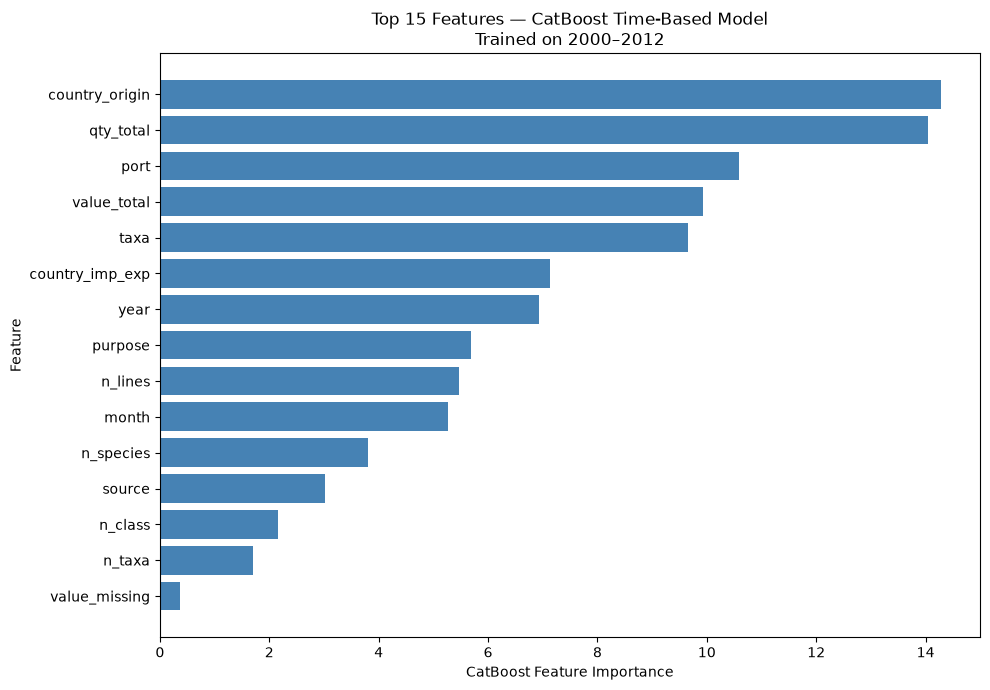

In [267]:

# ============================================================
# CATBOOST FEATURE IMPORTANCE — TIME-BASED MODEL
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

# 1. Use the existing trained model
model = catboost_model

# 2. Retrieve feature names from the trained model
feature_names = model.feature_names_

# 3. Calculate feature importance
importance_values = model.get_feature_importance(
    type="FeatureImportance"
)

# 4. Create and rank the importance table
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_values
})

feature_importance = (
    feature_importance
    .sort_values("Importance", ascending=False)
    .reset_index(drop=True)
)

# 5. Calculate percentage contribution
total_importance = feature_importance["Importance"].sum()

feature_importance["Importance_%"] = (
    feature_importance["Importance"] / total_importance * 100
    if total_importance > 0
    else 0
)

print("=" * 70)
print("CATBOOST FEATURE IMPORTANCE — TIME-BASED MODEL")
print("=" * 70)

display(
    feature_importance.style.format({
        "Importance": "{:.2f}",
        "Importance_%": "{:.2f}%"
    })
)

# ============================================================
# TOP 15 FEATURES
# ============================================================

top_features = (
    feature_importance
    .head(15)
    .sort_values("Importance", ascending=True)
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"],
    color="steelblue"
)

plt.xlabel("CatBoost Feature Importance")
plt.ylabel("Feature")
plt.title(
    "Top 15 Features — CatBoost Time-Based Model\n"
    "Trained on 2000–2012"
)

plt.tight_layout()
plt.show()

Interpretation

Shipment characteristics: qty_total is the most important predictor, followed by value_total. Together, they account for 25.84% of the reported feature importance.

Geographic characteristics: country_origin, port, and country_imp_exp collectively account for 32.24%, indicating that geographic and trade-route information contributes substantially to the model's predictions.

Biological and shipment structure: taxa, n_lines, n_species, n_class, and n_taxa provide additional predictive information.

Temporal patterns: year and month together account for 11.97%, suggesting that time-related information helps distinguish between outcomes.

Missingness: value_missing contributes only 0.19%, making it the least important feature according to this measure.

Overall, the model draws on multiple sources of information rather than relying on a single dominant predictor. These percentages describe the model's relative feature importance; they do not establish causal effects or indicate whether a feature increases or decreases the probability of a refused/seized outcome.

1. Clarify the evaluation metrics. PR-AUC of 0.6511 and ROC-AUC of 0.9301 should be explicitly attributed to the initial test evaluation, unless you have confirmed that they are also the metrics for the 2013–2014 out-of-time evaluation.

2. Qualify the generalization claim. The results support generalization to the 2013–2014 period, but do not establish that performance will remain stable in substantially later periods or under changes in inspection policy and shipment patterns.

3. Explain the operational trade-off. At 1% inspection capacity, the model captures 38.65% of positive cases with 91.50% precision. At 20% capacity, recall rises to 84.91%, while precision falls to 10.05%. This illustrates the trade-off between inspection resources and positive-case detection.

4. Distinguish lift from causal improvement. The reported lift values demonstrate enrichment relative to the overall positive-case rate. They do not, by themselves, establish a causal reduction in risk or prove that the inspection strategy improves final enforcement outcomes.

5. Strengthen the baseline comparison. Random inspection provides a useful benchmark. Assuming random selection from the evaluation population, its expected recall at an inspection rate of 1% would be approximately 1%, compared with the model's observed 38.65%. This comparison makes the practical value of risk ranking easier to understand.

Overall conclusion: The findings support CatBoost as a promising tool for ranking shipments by their predicted likelihood of refused/seized outcomes. Its value lies in concentrating positive cases among a limited number of inspections, while the out-of-time evaluation provides evidence of temporal generalization. The model should nevertheless be treated as a decision-support tool, with further monitoring, calibration assessment, and operational validation before deployment.

### Research Questions and Findings

**1. What shipment characteristics are associated with refused/seized outcomes?**

The exploratory analysis and CatBoost feature-importance results indicate that several shipment characteristics contributed to predicting refused/seized outcomes. The most important predictors in the time-based CatBoost model were **quantity (`qty_total`)**, **country of origin**, **port**, and **shipment value (`value_total`)**. Other useful predictors included taxonomic category, import/export country, year, number of lines, month, purpose, and source. These results describe predictive associations identified by the model and should not be interpreted as evidence of causal relationships.

**2. Can machine-learning models predict these outcomes?**

Yes. Four classification approaches were evaluated: **Logistic Regression, Decision Tree, Random Forest, and CatBoost**. Because only approximately **2.3% of shipments** were positive cases, PR-AUC was emphasized rather than accuracy. The models were able to distinguish positive from negative shipments, with CatBoost producing particularly strong discrimination in the initial evaluation.

**3. Which model provides the best ranking of high-risk shipments?**

CatBoost produced the strongest ranking performance among the evaluated models in the reported results. In the initial test evaluation, it achieved a **PR-AUC of 0.6511** and **ROC-AUC of 0.9301**. The model was therefore selected for the inspection-ranking simulation.

**4. How does performance change as inspection capacity changes?**

As inspection capacity increases, the model identifies more positive shipments and recall increases, but precision decreases because increasingly lower-ranked shipments are included. In the 2013–2014 out-of-time simulation, inspecting the highest-risk **1%** of shipments identified **38.65% of all positive cases**, while inspecting **20%** identified **84.91%**. Precision decreased from **91.50%** at 1% inspection to **10.05%** at 20% inspection.

**5. How much improvement does targeted inspection provide over random inspection?**

Targeted inspection substantially increased the concentration of positive cases among inspected shipments compared with the overall evaluation population. In the 2013–2014 simulation, the model produced a **38.65× lift** at a 1% inspection rate, **30.46× lift** at 2%, **14.34× lift** at 5%, **7.86× lift** at 10%, and **4.25× lift** at 20%. Thus, the model's ranking concentrated positive cases much more strongly than an inspection strategy that did not use the predicted risk scores.

**6. Does the model generalize to later years?**

Yes, the project directly evaluates this question using an **out-of-time validation design**. Shipments from **2000–2012** were used as the development period, while shipments from **2013–2014** were held out as a later-year evaluation period. The periods contain **178,518** and **29,413** shipments respectively, with positive rates of **2.30%** and **2.37%**, indicating similar outcome prevalence.

The CatBoost model was trained only on the 2000–2012 development data and then applied to the previously unseen 2013–2014 shipments. The out-of-time inspection simulation continued to show strong ranking performance: at a 1% inspection rate, **269 of 696 positive cases** were identified, corresponding to **38.65% recall**, **91.50% precision**, and **38.65× lift**. At a 20% inspection rate, the model identified **591 positive cases**, corresponding to **84.91% recall** and **4.25× lift**.

Therefore, the results provide evidence that the CatBoost model's risk-ranking ability **generalizes to the later 2013–2014 period**, rather than being limited to the historical observations used for model development. The out-of-time design is particularly important because it evaluates the model under a setting that more closely resembles deployment on future shipments.


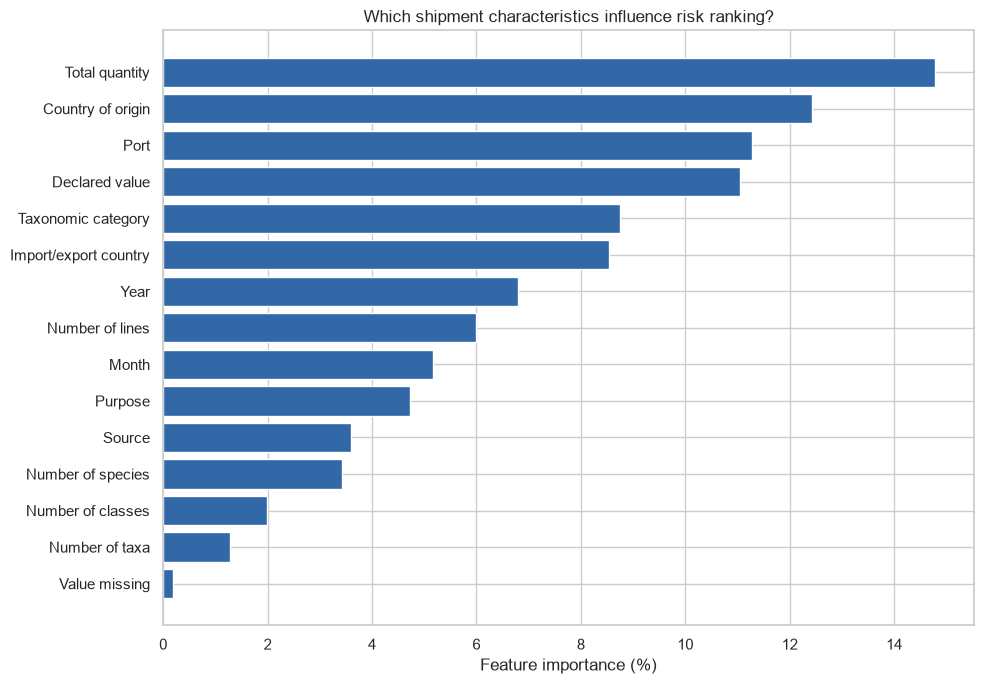

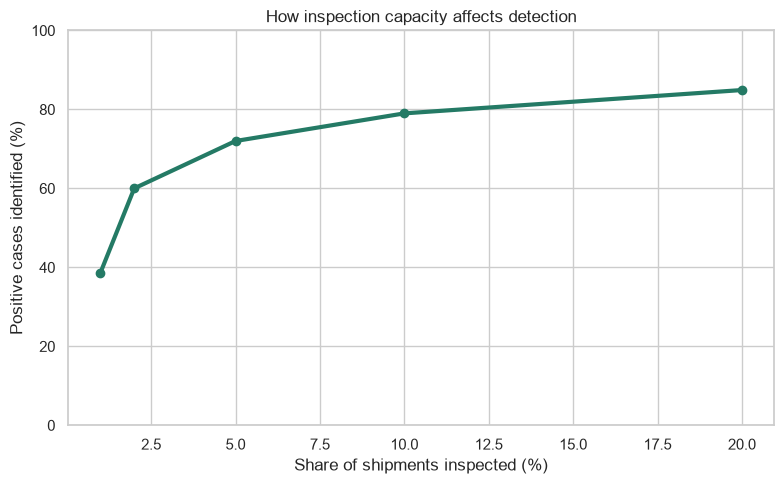

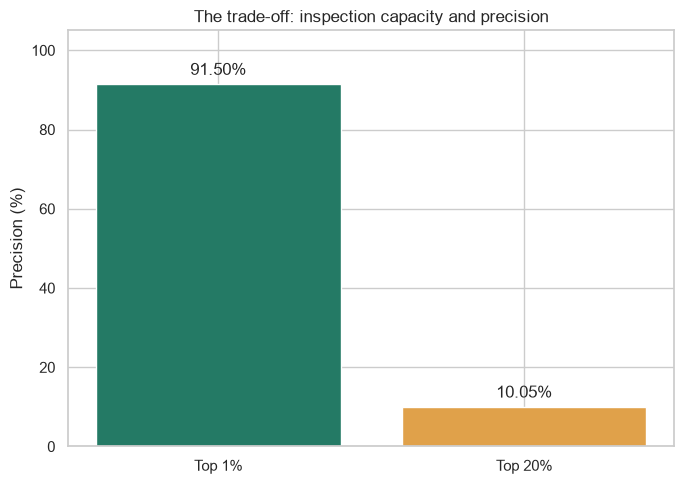

In [268]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Create a folder for the executive presentation charts
os.makedirs("executive_charts", exist_ok=True)

sns.set_theme(style="whitegrid", font_scale=1.0)

# 1. CatBoost feature importance
features = pd.DataFrame({
    "Feature": [
        "Total quantity", "Country of origin", "Port",
        "Declared value", "Taxonomic category",
        "Import/export country", "Year", "Number of lines",
        "Month", "Purpose", "Source", "Number of species",
        "Number of classes", "Number of taxa", "Value missing"
    ],
    "Importance": [
        14.79, 12.43, 11.28, 11.05, 8.75, 8.53, 6.80,
        6.00, 5.17, 4.73, 3.60, 3.42, 1.99, 1.28, 0.19
    ]
}).sort_values("Importance", ascending=True)

plt.figure(figsize=(10, 7))
plt.barh(features["Feature"], features["Importance"],
         color="#3267A8")
plt.xlabel("Feature importance (%)")
plt.title("Which shipment characteristics influence risk ranking?")
plt.tight_layout()
plt.savefig("executive_charts/slide3_feature_importance.png",
            dpi=300, bbox_inches="tight")
plt.show()

# 2. Inspection capacity and recall
# Values reflect the reported out-of-time simulation.
inspection = pd.DataFrame({
    "Inspection rate (%)": [1, 2, 5, 10, 20],
    "Recall (%)": [38.65, 60.0, 72.0, 79.0, 84.91]
})

plt.figure(figsize=(8, 5))
plt.plot(inspection["Inspection rate (%)"],
         inspection["Recall (%)"],
         marker="o", linewidth=3, color="#247A65")
plt.xlabel("Share of shipments inspected (%)")
plt.ylabel("Positive cases identified (%)")
plt.title("How inspection capacity affects detection")
plt.ylim(0, 100)
plt.tight_layout()
plt.savefig("executive_charts/slide4_recall.png",
            dpi=300, bbox_inches="tight")
plt.show()

# 3. Precision comparison at the reported endpoints
precision = pd.DataFrame({
    "Inspection rate": ["Top 1%", "Top 20%"],
    "Precision (%)": [91.50, 10.05]
})

plt.figure(figsize=(7, 5))
bars = plt.bar(precision["Inspection rate"],
               precision["Precision (%)"],
               color=["#247A65", "#E0A14A"])
plt.bar_label(bars, fmt="%.2f%%", padding=4)
plt.ylabel("Precision (%)")
plt.title("The trade-off: inspection capacity and precision")
plt.ylim(0, 105)
plt.tight_layout()
plt.savefig("executive_charts/slide5_precision.png",
            dpi=300, bbox_inches="tight")
plt.show()

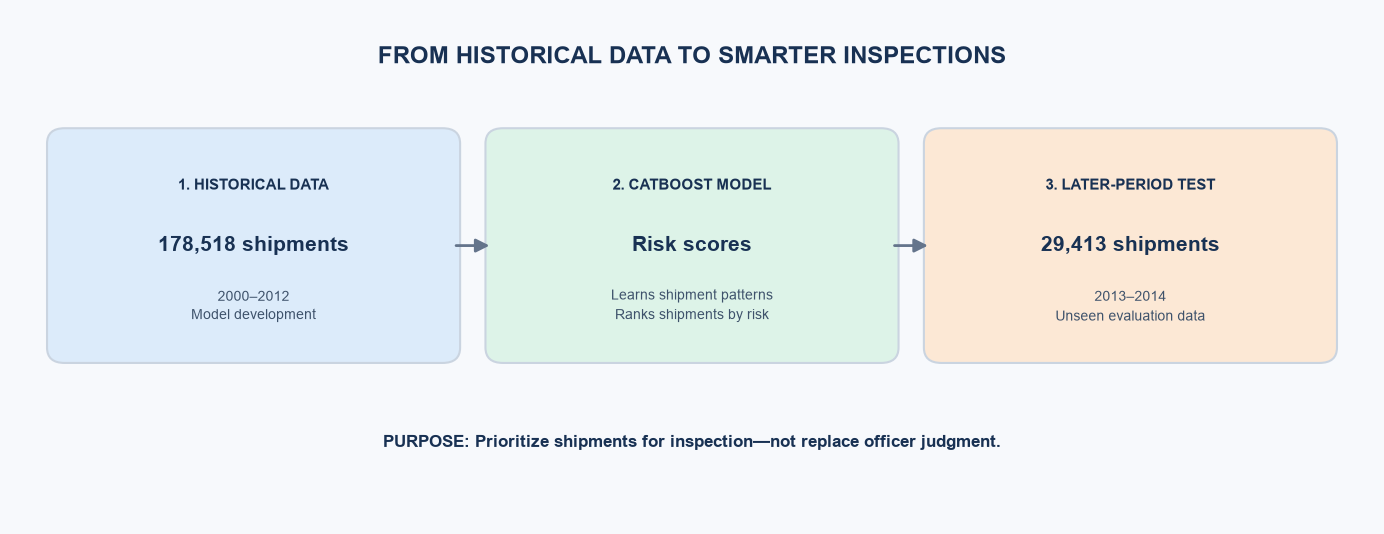

In [269]:

import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

# Create figure
fig, ax = plt.subplots(figsize=(14, 5.5))
fig.patch.set_facecolor("#F7F9FC")
ax.set_facecolor("#F7F9FC")
ax.set_xlim(0, 14)
ax.set_ylim(0, 6)
ax.axis("off")

# Title
ax.text(
    7, 5.45,
    "FROM HISTORICAL DATA TO SMARTER INSPECTIONS",
    ha="center", va="center",
    fontsize=17, fontweight="bold", color="#183153"
)

# Workflow boxes
boxes = [
    {
        "x": 0.5, "color": "#DCEBFA",
        "title": "1. HISTORICAL DATA",
        "main": "178,518 shipments",
        "detail": "2000–2012\nModel development"
    },
    {
        "x": 5.0, "color": "#DDF3E8",
        "title": "2. CATBOOST MODEL",
        "main": "Risk scores",
        "detail": "Learns shipment patterns\nRanks shipments by risk"
    },
    {
        "x": 9.5, "color": "#FCE8D5",
        "title": "3. LATER-PERIOD TEST",
        "main": "29,413 shipments",
        "detail": "2013–2014\nUnseen evaluation data"
    }
]

box_width = 4
box_height = 2.5
y = 2.0

for b in boxes:
    patch = FancyBboxPatch(
        (b["x"], y), box_width, box_height,
        boxstyle="round,pad=0.12,rounding_size=0.18",
        linewidth=1.5, edgecolor="#CAD4E0",
        facecolor=b["color"]
    )
    ax.add_patch(patch)

    ax.text(
        b["x"] + box_width/2, y + 1.95,
        b["title"], ha="center", va="center",
        fontsize=11, fontweight="bold", color="#183153"
    )
    ax.text(
        b["x"] + box_width/2, y + 1.25,
        b["main"], ha="center", va="center",
        fontsize=15, fontweight="bold", color="#183153"
    )
    ax.text(
        b["x"] + box_width/2, y + 0.55,
        b["detail"], ha="center", va="center",
        fontsize=10, color="#3E526B", linespacing=1.5
    )

# Arrows between boxes
for start, end in [(4.55, 4.95), (9.05, 9.45)]:
    arrow = FancyArrowPatch(
        (start, 3.25), (end, 3.25),
        arrowstyle="-|>", mutation_scale=20,
        linewidth=2, color="#64748B"
    )
    ax.add_patch(arrow)

# Bottom takeaway
ax.text(
    7, 0.95,
    "PURPOSE: Prioritize shipments for inspection—not replace officer judgment.",
    ha="center", va="center",
    fontsize=12, fontweight="bold", color="#183153"
)

plt.tight_layout()

# Save high-resolution image for PowerPoint
plt.savefig(
    "slide2_model_workflow.png",
    dpi=300, bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.show()

In [1]:
# Data manipulation
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing and modeling
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    RandomizedSearchCV
)

# Model evaluation
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    PrecisionRecallDisplay,
    RocCurveDisplay
)

# CatBoost
from catboost import CatBoostClassifier

# Display settings and reproducibility
pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", "{:.4f}".format)

RANDOM_STATE = 42

sns.set_theme(style="whitegrid")

# Model Brief: Shipment Inspection Prioritization

**Audience:** Technical colleagues and project stakeholders
**Purpose:** Summarize the modeling approach, empirical findings, limitations, and recommended next steps.

## Modeling approach

The project evaluates whether shipment-level data can support risk-based inspection prioritization. Logistic Regression was developed as an interpretable baseline, while CatBoost was explored as a more flexible model capable of learning nonlinear patterns and interactions among shipment attributes.

Because positive cases are relatively uncommon, model assessment emphasizes minority-class performance and ranking quality rather than accuracy alone. The evaluation strategy also uses a later-year holdout to investigate whether predictive performance transfers beyond the development period.

## What the results indicate

The Logistic Regression baseline achieved a ROC-AUC of 0.8963 and average precision of 0.3908 on the reported test set. At its default threshold, it identified approximately 79% of positive cases, but precision was approximately 11%. This illustrates an important operational trade-off: detecting more positive cases can require inspecting many shipments that ultimately are not positive.

The CatBoost inspection simulation provides a more directly operational view of ranking performance. The reported results indicate that the highest-risk 1% of shipments contained 282 of 696 positive cases, corresponding to approximately 40.5% recall and 95.6% precision within that inspected group. At a 5% inspection rate, the simulation identified 592 positive cases, or approximately 85.1% of all positive cases.

These findings suggest that ranking shipments by predicted risk may help concentrate inspection effort. However, the results are retrospective and should not be interpreted as proof of future operational performance.

## Modeling decisions and limitations

The baseline provides a reference point for predictive performance and interpretability. CatBoost provides a complementary approach for capturing more complex relationships. The final model should be selected only after both models are evaluated on identical time-based holdout records using the same metrics.

Important limitations include class imbalance, potential changes in shipment patterns over time, missing or inconsistent source data, and the possibility that historical inspection labels reflect previous inspection-selection policies rather than the true prevalence of positive cases across all shipments. Feature importance describes predictive contribution and does not establish causality.

The inspection simulation also assumes that the highest-ranked shipments can be inspected under the stated capacity constraints and that the historical labels are suitable for evaluating the outcomes. Actual inspection costs, operational constraints, and the consequences of missed positive cases may alter the optimal inspection rate.

## Recommended next steps

1. Complete a controlled comparison of Logistic Regression and CatBoost on the same later-year holdout.
2. Tune model hyperparameters using development and validation data without using holdout outcomes for model selection.
3. Assess precision, recall, and average precision across multiple time periods to quantify temporal stability.
4. Evaluate calibration and select operational thresholds based on inspection capacity and the relative costs of false positives and false negatives.
5. Investigate possible label bias, data leakage, and distribution shifts.
6. Before deployment, conduct prospective monitoring and assess whether the model improves inspection outcomes compared with existing practices.

## Recommendation

Treat the current model as a candidate decision-support tool rather than an autonomous inspection decision-maker. Its value should be judged by its ability to identify more positive cases within realistic inspection constraints, while maintaining transparency, monitoring performance over time, and accounting for the limitations of historical labels.
